# EDA na Prática

Nas aulas 9 e 10 vimos os quatro princípios da EDA (estrutural, distribucional, relacional e detecção de outliers/anomalias), como tratar dados ausentes e outliers, e como fazer análise descritiva, bivariada e multivariada. Hoje é a hora de **aplicarmos na prática**. Durante a primeira hora da aula, serão apresentadas as técnicas no dataset *Heart Disease* (UCI) e depois **cada aluno** irá aplicar as técnicas no dataset que foi escolhido semana passada.

*Relembrando*: a EDA não é uma linha reta

A EDA costuma ser apresentada como uma sequência de etapas (estrutura → tratamento → descrição → relação), mas na prática ela é **iterativa**: às vezes tratamos um outlier, olhamos a estatística descritiva de novo, e percebemos que precisa voltar atrás. Hoje vamos deixar isso explícito: olhamos a estatística descritiva **antes** de tratar dados ausentes/outliers (pra saber *como* tratar) e **depois** (pra confirmar o efeito do tratamento).

## Como funcionará a atividade

- **Duração:** ~1h40min
- **Formato:** individual
- **Passo 1:** acompanhem a demonstração no dataset Heart Disease.
- **Passo 2:** importem o dataset que vocês escolheram e enviaram anteriormente.
- **Passo 3:** repliquem o mesmo ciclo no dataset escolhido, respondendo às perguntas guiadas.
- **Uso de IA:** permitido, conforme o Plano de Ensino — documentem na seção final.

## Setup de Bibliotecas e Dados

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)

COR_NEUTRA = "lightgray"     # convenção: cinza-claro pra tudo que é "pano de fundo" genérico
COR_CONTEXTO = "#e9d4d0"    # rosa-claro pra pano de fundo / classe de referência
COR_DESTAQUE = "#2d223a"    # roxo pra classe de interesse / "o personagem da história"
COR_ALERTA = "tab:red"       # exceção deliberada: outliers/pontos de atenção

ModuleNotFoundError: No module named 'pandas'

## Carregando o Dataset

In [ ]:
# Install dependencies as needed:
# pip install kagglehub[pandas-datasets]
import kagglehub
from kagglehub import KaggleDatasetAdapter
import os

# 1. Baixa o dataset e lista os arquivos disponíveis
download_path = kagglehub.dataset_download("cuecacuela/brazilian-football-matches")
files = os.listdir(download_path)
print("Arquivos encontrados:", files)

# 2. Pega o primeiro arquivo de dados (ajuste o índice se houver mais de um)
file_path = files[0]
print("Usando arquivo:", file_path)

# 3. Carrega como DataFrame
df = kagglehub.dataset_load(
    KaggleDatasetAdapter.PANDAS,
    "cuecacuela/brazilian-football-matches",
    file_path,
)

print("First 5 records:")
print(df.head())

100%|██████████| 192k/192k [00:00<00:00, 430kB/s]

Extracting files...


Arquivos encontrados: ['BR-Football-Dataset.csv']
Usando arquivo: BR-Football-Dataset.csv
Using Colab cache for faster access to the 'brazilian-football-matches' dataset.
First 5 records:
       tournament       home  home_goal  away_goal         away  home_corner  \
0  Copa do Brasil  Sao Paulo        1.0        1.0     Flamengo          2.0   
1  Copa do Brasil   Flamengo        0.0        1.0    Sao Paulo          3.0   
2  Copa do Brasil   Flamengo        1.0        0.0       Gremio          6.0   
3  Copa do Brasil  Sao Paulo        2.0        0.0  Corinthians          7.0   
4  Copa do Brasil     Gremio        0.0        2.0     Flamengo          6.0   

   away_corner  home_attack  away_attack  home_shots  away_shots      time  \
0          4.0         75.0        104.0         8.0        13.0  20:00:00   
1          4.0        121.0         81.0         6.0         5.0  20:00:00   
2          6.0        101.0        115.0        12.0        15.0  01:30:00   
3          3.0     

## 1. Princípio Estrutural

Antes de qualquer análise, precisamos entender a "anatomia" dos dados: quantas linhas e colunas temos, que tipo de dado cada coluna guarda, se há valores faltantes e se há duplicadas.

**Antes de rodar:** o Heart Disease tem 13 variáveis preditoras (idade, sexo, tipo de dor no peito, pressão em repouso, colesterol, entre outras) mais o alvo (`num`, presença/grau de doença cardíaca). Quantas linhas vocês esperam que um dataset clínico como esse tenha — dezenas, centenas ou milhares de pacientes?

### Dimensão e Tipos de Dados

In [ ]:
df.shape

(10296, 18)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10296 entries, 0 to 10295
Data columns (total 18 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   tournament     10296 non-null  object 
 1   home           10296 non-null  object 
 2   home_goal      10296 non-null  float64
 3   away_goal      10296 non-null  float64
 4   away           10296 non-null  object 
 5   home_corner    10296 non-null  float64
 6   away_corner    10296 non-null  float64
 7   home_attack    7939 non-null   float64
 8   away_attack    7938 non-null   float64
 9   home_shots     7951 non-null   float64
 10  away_shots     7945 non-null   float64
 11  time           10296 non-null  object 
 12  date           10296 non-null  object 
 13  ht_diff        10296 non-null  float64
 14  at_diff        10296 non-null  float64
 15  ht_result      10296 non-null  object 
 16  at_result      10296 non-null  object 
 17  total_corners  10296 non-null  float64
dtypes: flo

In [ ]:
df.describe()

,home_goal,away_goal,home_corner,away_corner,home_attack,away_attack,home_shots,away_shots,ht_diff,at_diff,total_corners
count,10296.000000,10296.000000,10296.000000,10296.000000,7939.000000,7938.000000,7951.000000,7945.000000,10296.000000,10296.000000,10296.000000
mean,1.347125,0.929681,5.905400,4.481255,104.938657,97.474427,13.299208,10.177848,0.417444,-0.417444,10.386655
std,1.135988,0.969926,3.083678,2.608247,26.625330,24.982719,5.149698,4.488175,1.470706,1.470706,3.550178
min,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,1.000000,-7.000000,-8.000000,0.000000
25%,1.000000,0.000000,4.000000,3.000000,87.000000,81.000000,10.000000,7.000000,0.000000,-1.000000,8.000000
50%,1.000000,1.000000,6.000000,4.000000,105.000000,97.000000,13.000000,10.000000,0.000000,0.000000,10.000000
75%,2.000000,1.000000,8.000000,6.000000,123.000000,114.000000,17.000000,13.000000,1.000000,0.000000,13.000000
max,9.000000,8.000000,23.000000,19.000000,252.000000,262.000000,36.000000,101.000000,8.000000,7.000000,26.000000


### Duplicadas

In [ ]:
df.duplicated().sum()

np.int64(0)

### Renomeando o atributo alvo para facilitar a interpretação
No dataset de futebol, `at_result` já registra o resultado final em categorias (`HOME_WIN`/`DRAW`/`AWAY_WIN`, confira os rótulos exatos com `.unique()`). Pra algumas análises específicas (como o T-Test/Mann-Whitney de 2 grupos, se quisermos usar isso em vez de ANOVA/Kruskal-Wallis), pode fazer sentido simplificar pra uma variável binária — por exemplo, "o mandante venceu" ou não — já que essa é a distinção mais estudada no efeito casa do futebol.


In [ ]:
df["mandante_venceu"] = np.where(df["at_result"] == "HOME_WIN", "Venceu", "Não venceu")
# ajuste "HOME_WIN" para o rótulo real retornado por df["at_result"].unique()
df["mandante_venceu"].value_counts()
df.head()

,tournament,home,home_goal,away_goal,away,home_corner,away_corner,home_attack,away_attack,home_shots,away_shots,time,date,ht_diff,at_diff,ht_result,at_result,total_corners,mandante_venceu
0,Copa do Brasil,Sao Paulo,1.0,1.0,Flamengo,2.0,4.0,75.0,104.0,8.0,13.0,20:00:00,2023-09-24,0.0,0.0,DRAW,DRAW,6.0,Não venceu
1,Copa do Brasil,Flamengo,0.0,1.0,Sao Paulo,3.0,4.0,121.0,81.0,6.0,5.0,20:00:00,2023-09-17,-1.0,1.0,LOST,WON,7.0,Não venceu
2,Copa do Brasil,Flamengo,1.0,0.0,Gremio,6.0,6.0,101.0,115.0,12.0,15.0,01:30:00,2023-08-17,1.0,-1.0,WON,LOST,12.0,Não venceu
3,Copa do Brasil,Sao Paulo,2.0,0.0,Corinthians,7.0,3.0,112.0,111.0,21.0,10.0,23:30:00,2023-08-16,2.0,-2.0,WON,LOST,10.0,Não venceu
4,Copa do Brasil,Gremio,0.0,2.0,Flamengo,6.0,3.0,88.0,131.0,12.0,12.0,01:30:00,2023-07-27,-2.0,2.0,LOST,WON,9.0,Não venceu


## 2. Dados Faltantes

In [ ]:
df.isna().sum()

,0
tournament,0
home,0
home_goal,0
away_goal,0
away,0
home_corner,0
away_corner,0
home_attack,2357
away_attack,2358
home_shots,2345


**Discussao:** Alguma feature tem dados ausentes nos seus dados?

---



---



*Resposta*: Sim, essas 4:
home_attack	2357
away_attack	2358
home_shots	2345
away_shots	2351

#### Identificando o mecanismo de dados ausentes

**Conhecimento de Domínio**

No dataset atual temos quatro features com dados ausentes: 'home_attack', 'away_attack', 'home_shots' e 'away_shots'.

Pelo contexto do domínio (estatísticas de partidas de futebol) observamos que:

* home_attack / away_attack - número de ataques (ofensivas construídas) do time mandante/visitante durante a partida
* home_shots / away_shots - número de finalizações (chutes a gol) do time mandante/visitante durante a partida

*Como os dados provavelmente foram coletados:*
- O dataset reúne 10.296 partidas de diferentes competições ('tournament') do futebol brasileiro, o que sugere agregação de múltiplas fontes ou períodos de coleta, e não um único boletim oficial por jogo.
- Colunas de resultado básico (gols, escanteios, data, horário) estão 100% preenchidas, o que indica que vêm de uma fonte "oficial"/estruturada (súmula ou placar), enquanto as estatísticas avançadas (ataques e finalizações) parecem ter sido obtidas de uma segunda fonte — como um provedor de estatísticas ao vivo (live stats) — nem sempre disponível para todos os jogos.

*Qual a natureza da fonte de dados:*
- Estatísticas avançadas de jogo (ataques, finalizações) costumam depender de rastreamento em tempo real (in-play tracking), serviço geralmente reservado a competições de maior visibilidade midiática — Série A do Brasileirão, por exemplo — enquanto campeonatos estaduais ou de menor divisão tendem a não ter esse detalhamento contratado.
- Como o dataset condensa 'tournament' diferentes (não especificado neste resumo se são só ligas nacionais ou também estaduais/copas), é plausível que os ~23% de nulos em 'attack' e 'shots' estejam concentrados em competições ou temporadas mais antigas/menos cobertas, e não distribuídos aleatoriamente pelo dataset — ou seja, um padrão provável de dados **MNAR (Missing Not At Random)**.
- Recomenda-se validar essa hipótese cruzando `df[df['home_attack'].isnull()]['tournament'].value_counts()` e `.describe()` de `date` antes de decidir a estratégia de tratamento.

**As ausencias ocorrem juntas?**

Contar ausentes por coluna não conta a história toda: se duas colunas ficam ausentes **nas mesmas linhas**, isso é um indício de padrão sistemático (ex: um exame que não foi feito, afetando várias medidas de uma vez).



In [ ]:
cols_com_ausentes = df.columns[df.isna().any()].tolist()
print("Colunas com ausentes:", cols_com_ausentes)
print(df[cols_com_ausentes].isna().sum())


Colunas com ausentes: ['home_attack', 'away_attack', 'home_shots', 'away_shots']
home_attack    2357
away_attack    2358
home_shots     2345
away_shots     2351
dtype: int64


Com poucos ausentes (no máximo poucas dezenas de linhas), uma correlação entre as colunas de ausência pode parecer precisa, mas na prática é calculada em cima de um poucos de casos, ou seja, número pequeno demais pra confiar no coeficiente. Aqui a contagem bruta (quantas linhas têm as duas ausências ao mesmo tempo) é mais honesta que uma correlação.

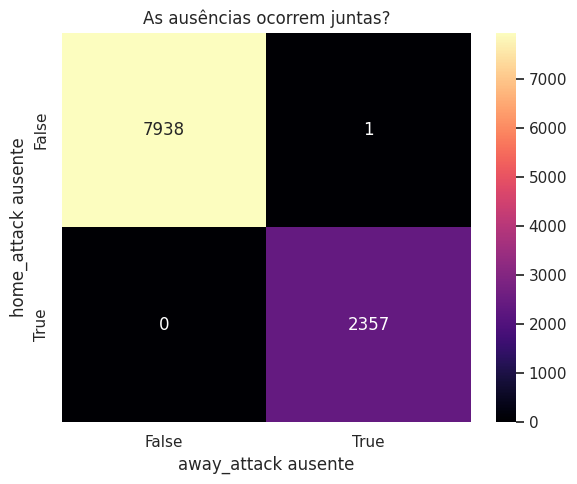

In [ ]:
tabela_contingencia = pd.crosstab(df[cols_com_ausentes[0]].isna(), df[cols_com_ausentes[1]].isna(),
            rownames=[f"{cols_com_ausentes[0]} ausente"], colnames=[f"{cols_com_ausentes[1]} ausente"])

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(tabela_contingencia, annot=True, fmt="d", cmap="magma", ax=ax)
ax.set_title("As ausências ocorrem juntas?")
plt.tight_layout()
plt.show()

**Pra discutir:** quantas linhas têm as duas colunas ausentes ao mesmo tempo? Isso muda a hipótese sobre o mecanismo de ausência (MCAR/MAR/MNAR), ou parecem eventos independentes?

*Relembrando:*
- MCAR: Mecanismo Aleatório e sem viés
- MAR: Mecanismo Randômico e com viés possível de corrigir
- MNAR: Mecanismo Não Randômico relacionada a própria feature

- *Se supormos que a ausência depende do próprio valor que está faltando*: por exemplo, o paciente não fez o exame porque já se suspeitava (por sinais clínicos observados previamente) que o resultado seria anormal, e o exame extra não seria necessário, isso seria classificado como **MNAR**.
- *Se supormos que a ausência depende de algo externo ao valor em si*: por exemplo, o protocolo de coleta decidiu não solicitar aquele exame, ou o custo do procedimento limitou a coleta, independente do que o resultado provavelmente seria — isso seria classificado como **MAR** (ou até **MCAR**, se a decisão for arbitrária e não sistemática).

Não dá pra decidir entre as duas só olhando os dados — é exatamente o tipo de situação em que testes estatísticos (como o teste de MCAR) e conhecimento de domínio real (falar com quem coletou os dados) resolveriam a dúvida. Na ausência disso, seguimos com a opção mais conservadora na hora de tratar.

**Nota para quando vocês replicarem no dataset de vocês:** se o dataset escolhido tiver *muitas* colunas com *muitos* ausentes, aí sim uma correlação (ou um heatmap) entre os indicadores de ausência passa a fazer sentido. O problema neste caso foi o volume pequeno, não a técnica em si.

## 3. Princípio Distribucional

Ainda com os dados originais (sem tratar ausentes ou outliers), vamos calcular as estatísticas descritivas e olhar as distribuições. Esse retrato "antes" é o que vai *orientar as decisões de tratamento* na próxima seção. Por exemplo, se uma variável for muito assimétrica, faz mais sentido imputar com a mediana do que com a média.

In [ ]:
VARS_QUANT = ["home_goal", "away_goal", "home_corner", "away_corner",
              "home_attack", "away_attack", "home_shots", "away_shots",
              "ht_diff", "at_diff", "total_corners"]
VARS_QUALI = ["tournament", "home", "away", "ht_result", "at_result"]

"""### Tabela descritiva, com assimetria e curtose"""

desc = df[VARS_QUANT].describe().T
desc["skewness"] = df[VARS_QUANT].skew()
desc["kurtosis"] = df[VARS_QUANT].kurtosis()

(
    desc[["mean", "50%", "std", "min", "max", "skewness", "kurtosis"]]
    .rename(columns={"50%": "median"})
    .round(2)
    .style.format(precision=2)
    .background_gradient(cmap="magma", subset=["skewness", "kurtosis"])
)

,mean,median,std,min,max,skewness,kurtosis
home_goal,1.35,1.00,1.14,0.00,9.00,0.87,1.00
away_goal,0.93,1.00,0.97,0.00,8.00,1.12,1.66
home_corner,5.91,6.00,3.08,0.00,23.00,0.71,0.65
away_corner,4.48,4.00,2.61,0.00,19.00,0.79,0.86
home_attack,104.94,105.00,26.63,1.00,252.00,0.03,0.35
away_attack,97.47,97.00,24.98,1.00,262.00,0.05,0.46
home_shots,13.30,13.00,5.15,1.00,36.00,0.50,0.32
away_shots,10.18,10.00,4.49,1.00,101.00,1.77,23.08
ht_diff,0.42,0.00,1.47,-7.00,8.00,0.06,0.73
at_diff,-0.42,0.00,1.47,-8.00,7.00,-0.06,0.73


**Pra discutir:** olhando a tabela, quais variáveis já parecem assimétricas (`skewness` acima de 1) ou com cauda pesada (`kurtosis` maior que 2 em módulo)?

Isso é coerente com o que vocês esperariam do domínio de futebol (ex: finalizações e gols costumam ter poucos jogos com valores muito altos, puxando a cauda direita, enquanto a diferença de gols tende a ficar concentrada perto de zero)?

**Quais variáveis são assimétricas ou têm cauda pesada:**
- Skewness > 1: `away_goal` (1.12) e `away_shots` (1.77)
- Kurtosis > 2 (em módulo): só `away_shots` (23.08) — isso é disparado, muito acima de todo o resto da tabela

As demais variáveis (`home_goal`, `home_corner`, `away_corner`, `home_attack`, `away_attack`, `home_shots`, `ht_diff`, `at_diff`, `total_corners`) ficam com skewness abaixo de 1 e kurtosis abaixo de 1 — ou seja, próximas de uma distribuição razoavelmente simétrica e sem cauda pesada.

**Isso é coerente com o domínio de futebol?**

Parcialmente. A parte que bate com a expectativa: gols (`home_goal`/`away_goal`) e finalizações (`home_shots`) têm assimetria moderada e positiva, o que é esperado — a maioria dos jogos tem poucos gols/chutes, e só alguns jogos "puxam" a cauda pra cima com goleadas ou domínio total de um time. A diferença de gols (`ht_diff`/`at_diff`) ficou praticamente simétrica em torno de zero, também como o esperado — jogos equilibrados são a norma, goleadas pra qualquer lado são raras e simétricas.

A parte que não bate: `away_shots` tem uma cauda tão mais pesada que todo o resto (kurtosis 23 contra no máximo ~1.7 nas outras variáveis) que não parece ser só "assimetria natural do domínio" — é um salto estatístico grande demais pra ser explicado só pela dinâmica normal do jogo. Combinado com o `max` de 101 finalizações (fisicamente improvável), a leitura mais provável não é "o visitante às vezes ataca muito mais", e sim que tem **erro de dado** poluindo essa coluna especificamente — o que muda a conclusão de "isso é o domínio" pra "isso precisa de limpeza antes de eu confiar no domínio".

### Distribuições de dados

Onde fizer sentido, comparamos "0x0" (vermelho) vs. "Com gol" (azul). Vamos utilizar esta convenção de cor que vamos manter até a análise bivariada.

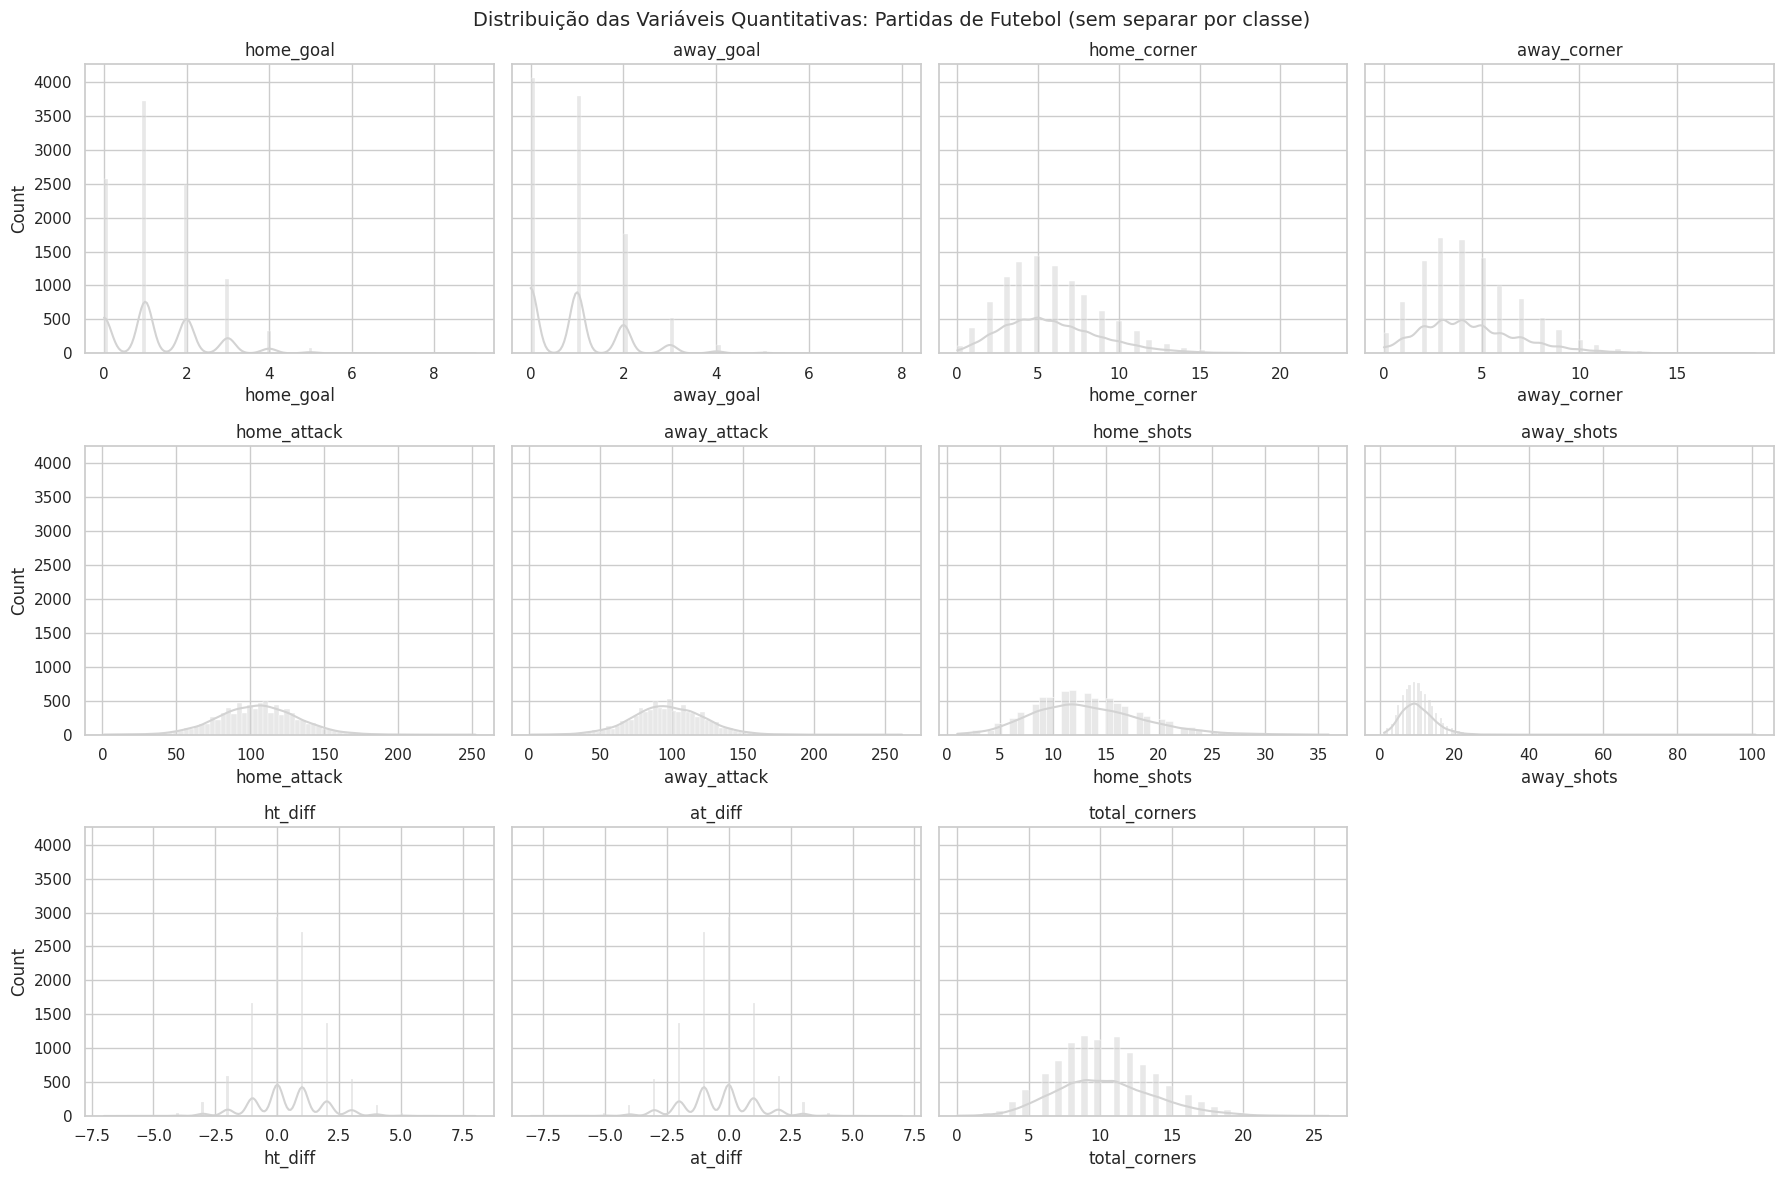

In [ ]:
fig, axes = plt.subplots(3, 4, figsize=(18, 12), sharey=True)
axes = axes.ravel()

for i, col in enumerate(VARS_QUANT):
    sns.histplot(data=df, x=col, kde=True, color=COR_NEUTRA, ax=axes[i])
    axes[i].set_title(col)

for ax in axes[len(VARS_QUANT):]:
    ax.axis("off")

fig.suptitle("Distribuição das Variáveis Quantitativas: Partidas de Futebol (sem separar por classe)", fontsize=14)
plt.tight_layout()
plt.show()

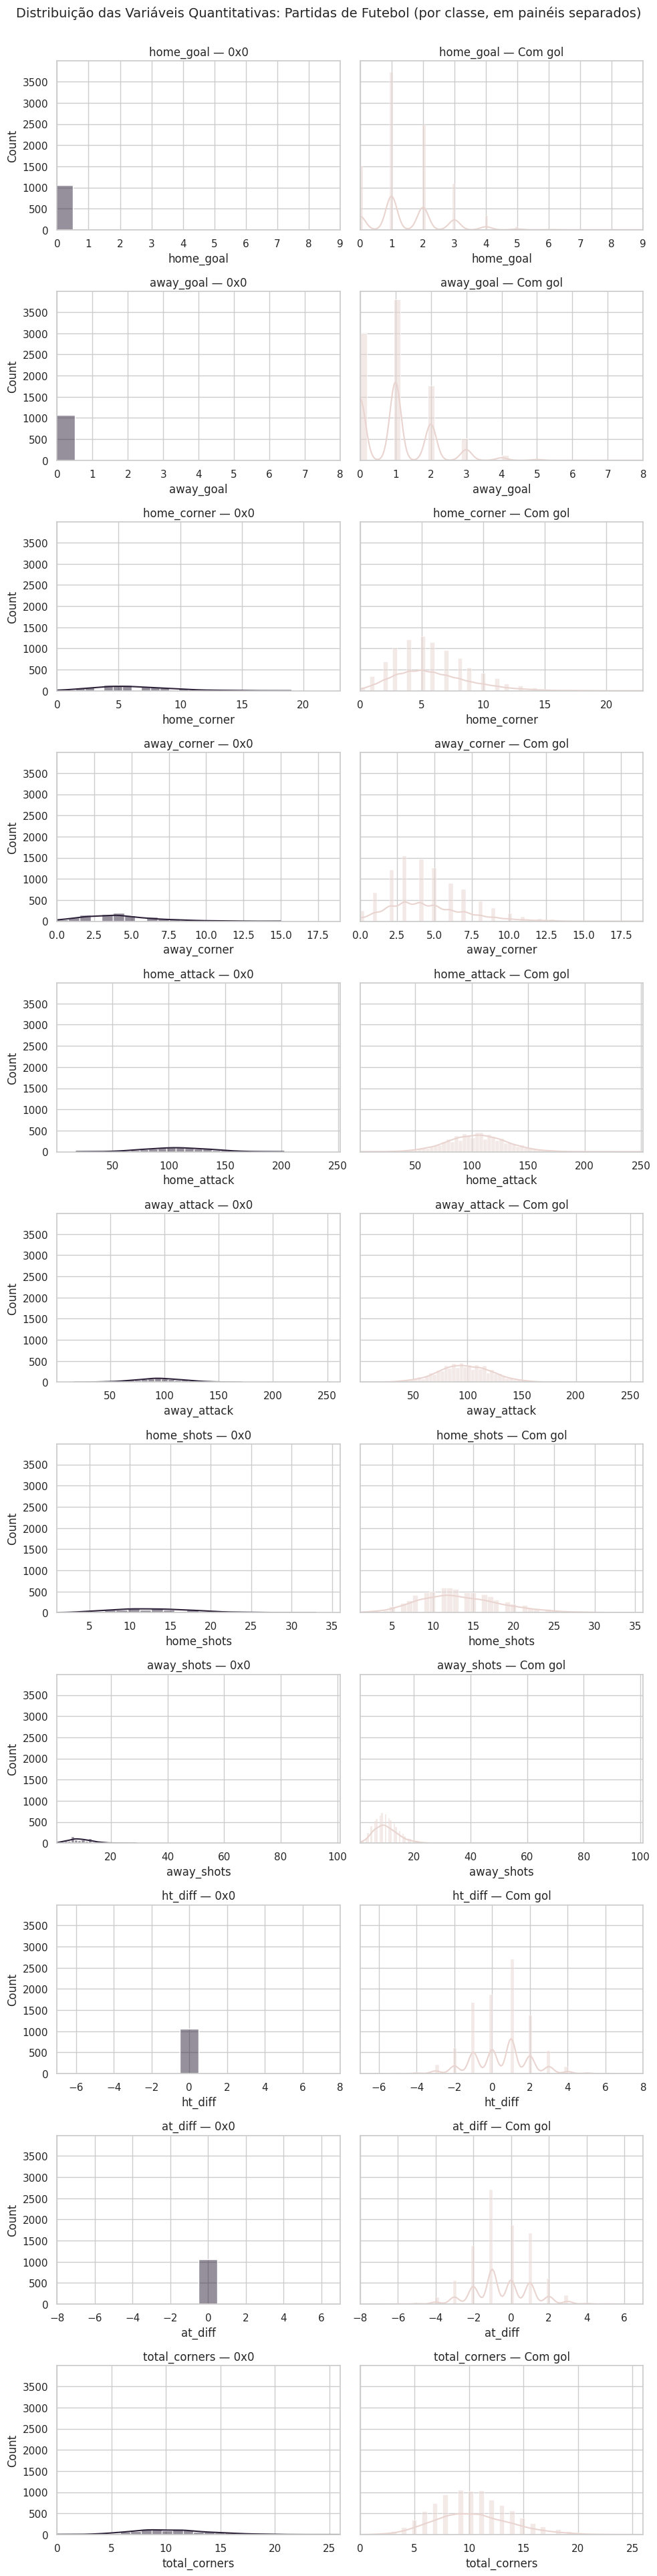

In [ ]:
df['jogo_com_gols'] = (df['home_goal'] + df['away_goal'] > 0).map({True: "Com gol", False: "0x0"})

fig, axes = plt.subplots(len(VARS_QUANT), 2, figsize=(10, 3.5 * len(VARS_QUANT)), sharey=True)

for i, col in enumerate(VARS_QUANT):
    lim = (df[col].min(), df[col].max())
    for j, (classe, cor) in enumerate([("0x0", COR_DESTAQUE), ("Com gol", COR_CONTEXTO)]):
        subset = df[df["jogo_com_gols"] == classe]
        sns.histplot(data=subset, x=col, kde=True, color=cor, ax=axes[i, j])
        axes[i, j].set_xlim(lim)
        axes[i, j].set_title(f"{col} — {classe}")

fig.suptitle("Distribuição das Variáveis Quantitativas: Partidas de Futebol (por classe, em painéis separados)", fontsize=14, y=1.001)
plt.tight_layout()
plt.show()

**Para discutir:** agora que as classes estão em painéis separados (mesma escala de eixo X em cada linha), fica mais fácil ver: alguma variável parece ter formato bem diferente entre "0x0" e "Com gol"?

> `home_shots` e `away_shots` devem ser as que mais mudam de formato — jogos com gol puxando pra mais finalizações.

#### Testes de Aderência

*Será se o total-corners segue uma distribuição normal?*

O **Shapiro-Wilk** como o teste de aderência mais usado pra normalidade, junto com o **QQ-Plot** como visualização de apoio. Vamos testar com `chol`.

/usr/local/lib/python3.13/dist-packages/scipy/stats/_axis_nan_policy.py:579: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 10296.
  res = hypotest_fun_out(*samples, **kwds)


Shapiro-Wilk - total_corners
Estatística: 0.9849
p-valor: 0.0000
Rejeitamos H0: a distribuição NÃO é normal (p < 0.05)


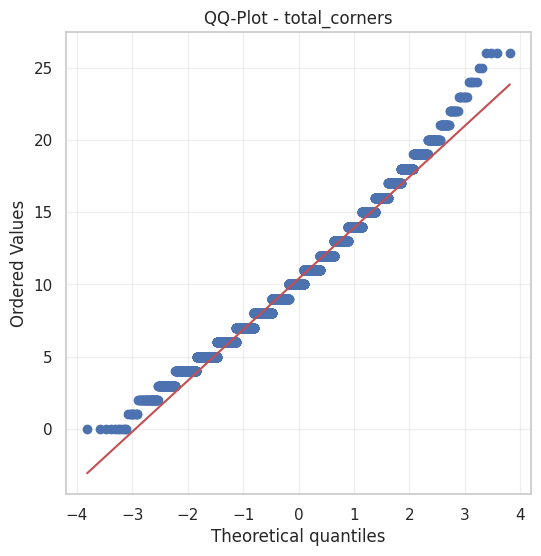

In [ ]:
import scipy.stats as stats
import matplotlib.pyplot as plt

# ---- Teste de Shapiro-Wilk ----
# H0: a variável segue distribuição normal
# H1: a variável NÃO segue distribuição normal
coluna = 'total_corners'
stat, p_valor = stats.shapiro(df[coluna].dropna())

print(f"Shapiro-Wilk - {coluna}")
print(f"Estatística: {stat:.4f}")
print(f"p-valor: {p_valor:.4f}")

if p_valor < 0.05:
    print("Rejeitamos H0: a distribuição NÃO é normal (p < 0.05)")
else:
    print("Não rejeitamos H0: não há evidência para dizer que não é normal (p >= 0.05)")

# ---- QQ-Plot (visualização de apoio) ----
plt.figure(figsize=(6, 6))
stats.probplot(df[coluna].dropna(), dist="norm", plot=plt)
plt.title(f"QQ-Plot - {coluna}")
plt.grid(alpha=0.3)
plt.show()

**Como ler:** se os pontos (roxo) seguissem a reta vermelha de perto, a variável seguiria uma normal. Pontos que se afastam da reta nas pontas indicam cauda mais pesada ou mais leve que a normal — coerente com o resultado do Shapiro-Wilk acima.

**Nota: cuidado com duas armadilhas de interpretação**

- **Tamanho da amostra e poder do teste:** é comum achar que "poucos dados" tornam mais fácil rejeitar a normalidade e é o contrário. Amostras **pequenas** têm **menos poder estatístico**, ou seja, tendem a *não* rejeitar mesmo quando os dados realmente não são normais. Já amostras **muito grandes** (milhares de linhas) deixam o teste sensível demais, rejeitando por desvios triviais. Com n≈303 (nem pequeno, nem enorme) e três evidências concordando — skewness alto, QQ-Plot afastado da reta, e Shapiro-Wilk rejeitando — o resultado é razoavelmente confiável, não um artefato do tamanho da amostra.
- **Como afirmar o resultado:** quando o teste **rejeita** H0 (nosso caso, p < 0.05), a afirmação correta é "temos evidência estatística **contra** a normalidade" que é uma conclusão forte. A frase "não podemos garantir normalidade" cabe no caso oposto: quando o teste **não rejeita** H0, já que a ausência de rejeição nunca prova que os dados são normais, só que não há evidência suficiente contra.

In [ ]:
VARS_QUANT = ['home_goal', 'away_goal', 'home_corner', 'away_corner',
              'home_attack', 'away_attack', 'home_shots', 'away_shots',
              'ht_diff', 'at_diff', 'total_corners']

resultados_shapiro = []
for col in VARS_QUANT:
    stat, p = stats.shapiro(df[col].dropna())
    resultados_shapiro.append({"variavel": col, "estatistica": round(stat, 4),
                                "p_valor": round(p, 6), "rejeita_normalidade": p < 0.05})

pd.DataFrame(resultados_shapiro).set_index("variavel")

/usr/local/lib/python3.13/dist-packages/scipy/stats/_axis_nan_policy.py:579: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 7939.
  res = hypotest_fun_out(*samples, **kwds)
/usr/local/lib/python3.13/dist-packages/scipy/stats/_axis_nan_policy.py:579: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 7938.
  res = hypotest_fun_out(*samples, **kwds)
/usr/local/lib/python3.13/dist-packages/scipy/stats/_axis_nan_policy.py:579: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 7951.
  res = hypotest_fun_out(*samples, **kwds)
/usr/local/lib/python3.13/dist-packages/scipy/stats/_axis_nan_policy.py:579: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 7945.
  res = hypotest_fun_out(*samples, **kwds)


,estatistica,p_valor,rejeita_normalidade
variavel,,,
home_goal,0.8775,0.000000,True
away_goal,0.8172,0.000000,True
home_corner,0.9616,0.000000,True
away_corner,0.9507,0.000000,True
home_attack,0.9987,0.000005,True
away_attack,0.9979,0.000000,True
home_shots,0.9825,0.000000,True
away_shots,0.9331,0.000000,True
ht_diff,0.9570,0.000000,True


**ECDF — outra forma de ver a distribuição**

Diferente do histograma, a ECDF não depende de escolher o número de bins: para cada valor no eixo X, a curva mostra a **proporção acumulada** de observações menores ou iguais àquele valor. É especialmente útil pra comparar duas distribuições lado a lado — onde as curvas se distanciam mais é onde a diferença entre os grupos é mais perceptível.

Vamos ilustrar com uma única variável (`home_attack`, ataques do mandante), só pra fixar como essa visualização se lê.

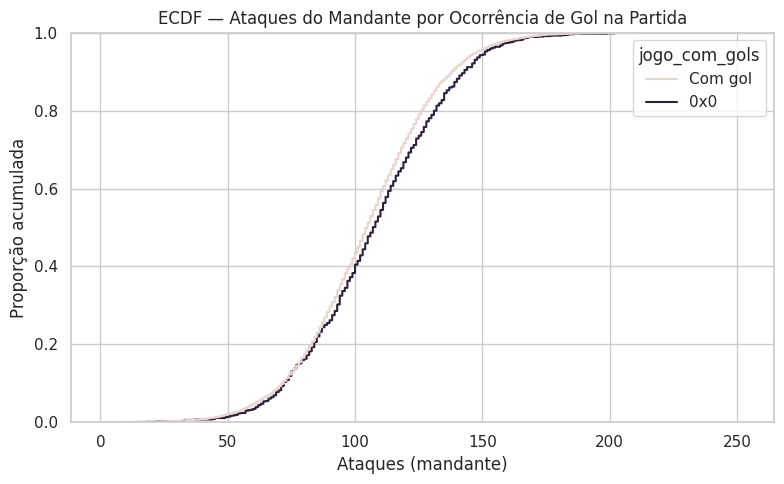

In [ ]:
df['jogo_com_gols'] = (df['home_goal'] + df['away_goal'] > 0).map({True: "Com gol", False: "0x0"})

plt.figure(figsize=(8, 5))
sns.ecdfplot(data=df, x="home_attack", hue="jogo_com_gols",
             palette={"Com gol": COR_CONTEXTO, "0x0": COR_DESTAQUE})
plt.title("ECDF — Ataques do Mandante por Ocorrência de Gol na Partida")
plt.xlabel("Ataques (mandante)")
plt.ylabel("Proporção acumulada")
plt.tight_layout()
plt.show()

Adaptando a leitura pro seu caso (usando o exemplo binário `jogo_com_gols`, já que é mais direto pra explicar com 2 curvas):

**Como ler:** em qualquer ponto do eixo X, a altura da curva diz "que fração das partidas desse grupo teve ataques do mandante até aqui". Onde as duas curvas (partidas com gol e partidas 0x0) se distanciam mais, ali está a faixa de `home_attack` onde os dois grupos mais diferem — sem precisar decidir uma largura de bin como no histograma.

Se optar pelo exemplo com 3 grupos (`at_result` — vitória mandante / empate / vitória visitante), a leitura muda um pouco porque não são mais duas curvas, e sim três se cruzando:

**Como ler (versão 3 grupos):** em qualquer ponto do eixo X, a altura de cada curva diz "que fração das partidas daquele resultado teve total de escanteios até aqui". Aqui o interessante não é só onde as curvas se distanciam mais entre si, mas também a **ordem** delas em cada faixa do eixo — se a curva de "vitória mandante" fica sistematicamente mais à direita (mais escanteios pra chegar na mesma proporção acumulada), é um indício de que jogos com mais escanteios tendem a favorecer o mandante.

Qual dos dois você vai usar no notebook final — a comparação binária ou a de 3 grupos? Isso muda se a legenda de cores deve ter 2 ou 3 entradas.

Métricas de Tendêncial Central

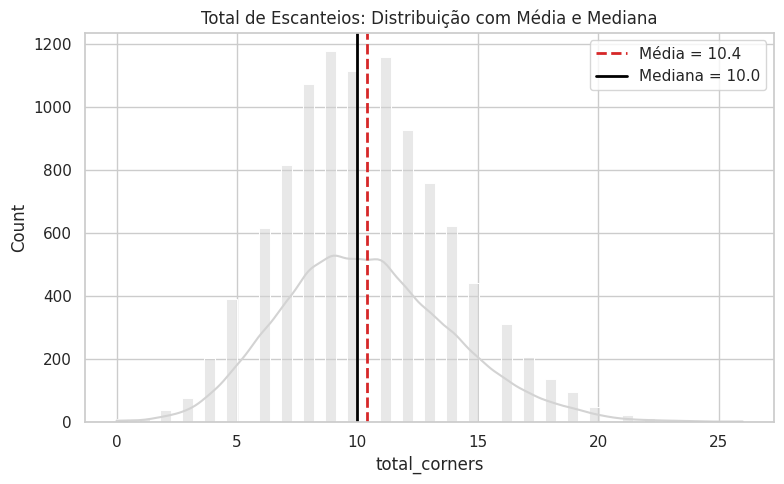

In [ ]:
media_corners = df["total_corners"].mean()
mediana_corners = df["total_corners"].median()

plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="total_corners", kde=True, color=COR_NEUTRA)
plt.axvline(media_corners, color=COR_ALERTA, linestyle="--", linewidth=2, label=f"Média = {media_corners:.1f}")
plt.axvline(mediana_corners, color="black", linestyle="-", linewidth=2, label=f"Mediana = {mediana_corners:.1f}")
plt.title("Total de Escanteios: Distribuição com Média e Mediana")
plt.legend()
plt.tight_layout()
plt.show()

### Dispersão

['DRAW', 'WON', 'LOST']


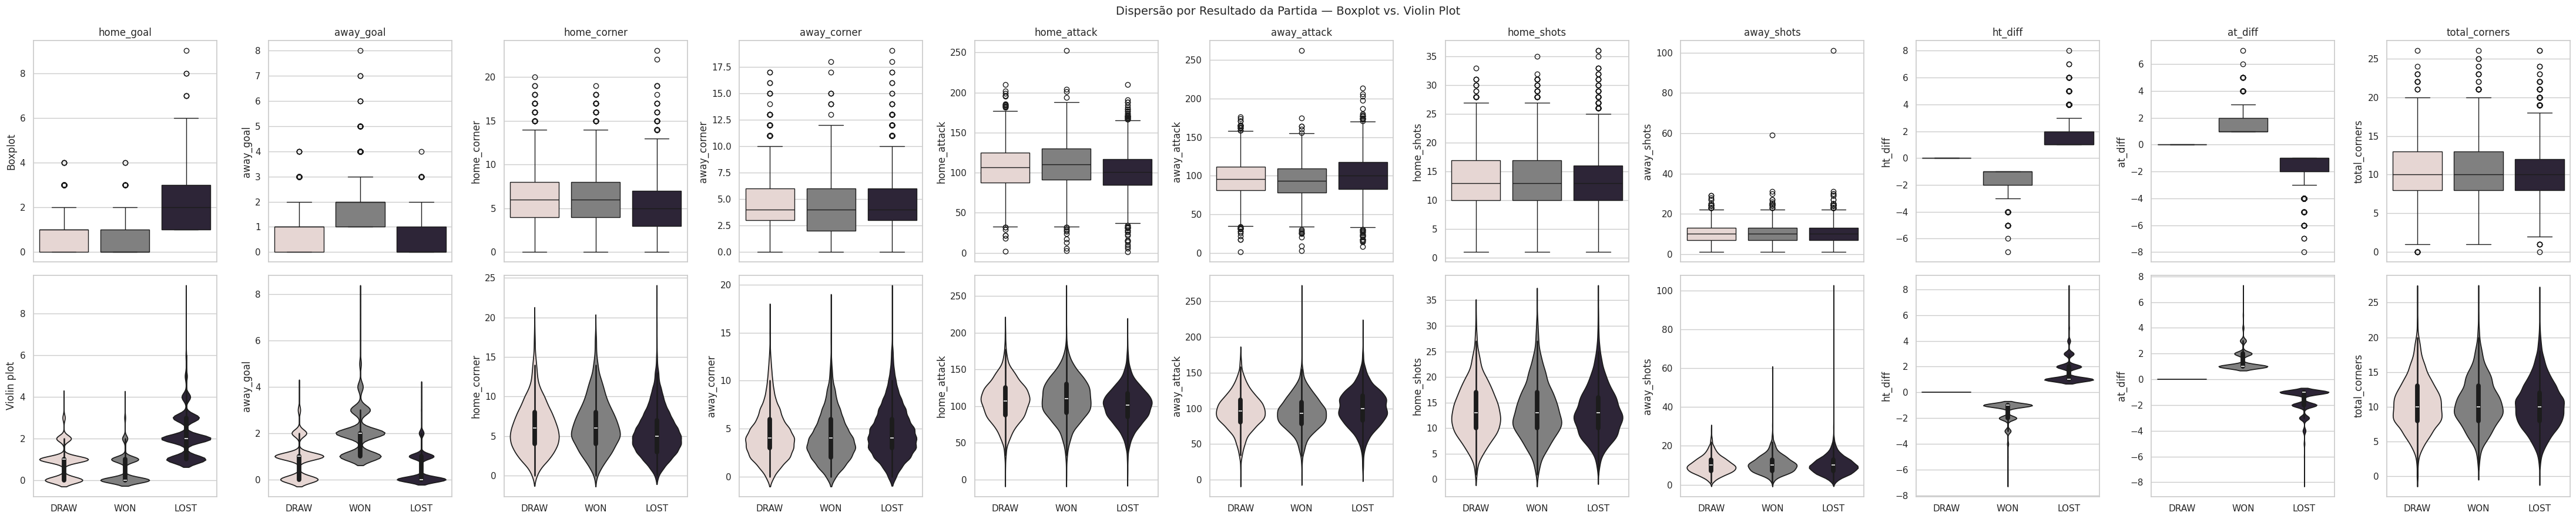

In [ ]:
dispersao = df[VARS_QUANT].agg(["var", "std"]).T
dispersao["IQR"] = df[VARS_QUANT].quantile(0.75) - df[VARS_QUANT].quantile(0.25)
dispersao.round(2)

"""### Boxplot e violin plot por classe"""

rotulos = df['at_result'].dropna().unique().tolist()
print(rotulos)  # confira aqui antes de seguir

cores_base = [COR_CONTEXTO, "gray", COR_DESTAQUE]
palette_classe = {rotulo: cores_base[i % len(cores_base)] for i, rotulo in enumerate(rotulos)}

fig, axes = plt.subplots(2, len(VARS_QUANT), figsize=(4 * len(VARS_QUANT), 9), sharex="col")

for i, col in enumerate(VARS_QUANT):
    sns.boxplot(data=df, x="at_result", y=col, hue="at_result",
                palette=palette_classe, legend=False, ax=axes[0, i])
    axes[0, i].set_title(col)
    axes[0, i].set_xlabel("")

    sns.violinplot(data=df, x="at_result", y=col, hue="at_result",
                    palette=palette_classe, legend=False, ax=axes[1, i])
    axes[1, i].set_xlabel("")

axes[0, 0].set_ylabel("Boxplot")
axes[1, 0].set_ylabel("Violin plot")
fig.suptitle("Dispersão por Resultado da Partida — Boxplot vs. Violin Plot", fontsize=14)
plt.tight_layout()
plt.show()

**Pra discutir:** alguma variável mostra uma caixa (IQR) nitidamente mais alta ou mais baixa entre os resultados de partida ("Vitória Mandante", "Empate", "Vitória Visitante")? Isso já é um indício — antes mesmo da análise bivariada formal — de que essa variável pode ajudar a diferenciar os desfechos do jogo.

## 4. Tratamento de Dados Ausentes e Outliers

Agora que já vimos o retrato estatístico "antes" (Seção 3), temos a informação que faltava pra decidir como tratar tanto os dados ausentes (`home_attack`, `away_attack`, `home_shots`, `away_shots`) quanto os outliers das variáveis quantitativas (com destaque pra `away_shots`, já sinalizado). Depois do tratamento, vamos rodar a estatística descritiva mais uma vez ("depois") pra confirmar o efeito das escolhas e fechar o ciclo iterativo que começamos lá na abertura.

### Detecção de Outliers por IQR

A regra clássica marca como outlier qualquer ponto fora de `[Q1 - 1.5*IQR, Q3 + 1.5*IQR]`.

In [ ]:
def limites_iqr(serie):
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

resumo_outliers = {}
for col in VARS_QUANT:
    lim_inf, lim_sup = limites_iqr(df[col])
    n_outliers = ((df[col] < lim_inf) | (df[col] > lim_sup)).sum()
    resumo_outliers[col] = {
        "limite_inferior": round(lim_inf, 2),
        "limite_superior": round(lim_sup, 2),
        "n_outliers": n_outliers,
    }

pd.DataFrame(resumo_outliers).T

,limite_inferior,limite_superior,n_outliers
home_goal,-0.5,3.5,443.0
away_goal,-1.5,2.5,680.0
home_corner,-2.0,14.0,104.0
away_corner,-1.5,10.5,255.0
home_attack,33.0,177.0,71.0
away_attack,31.5,163.5,82.0
home_shots,-0.5,27.5,76.0
away_shots,-2.0,22.0,74.0
ht_diff,-1.5,2.5,1608.0
at_diff,-2.5,1.5,1608.0


### Visualizando os Outliers

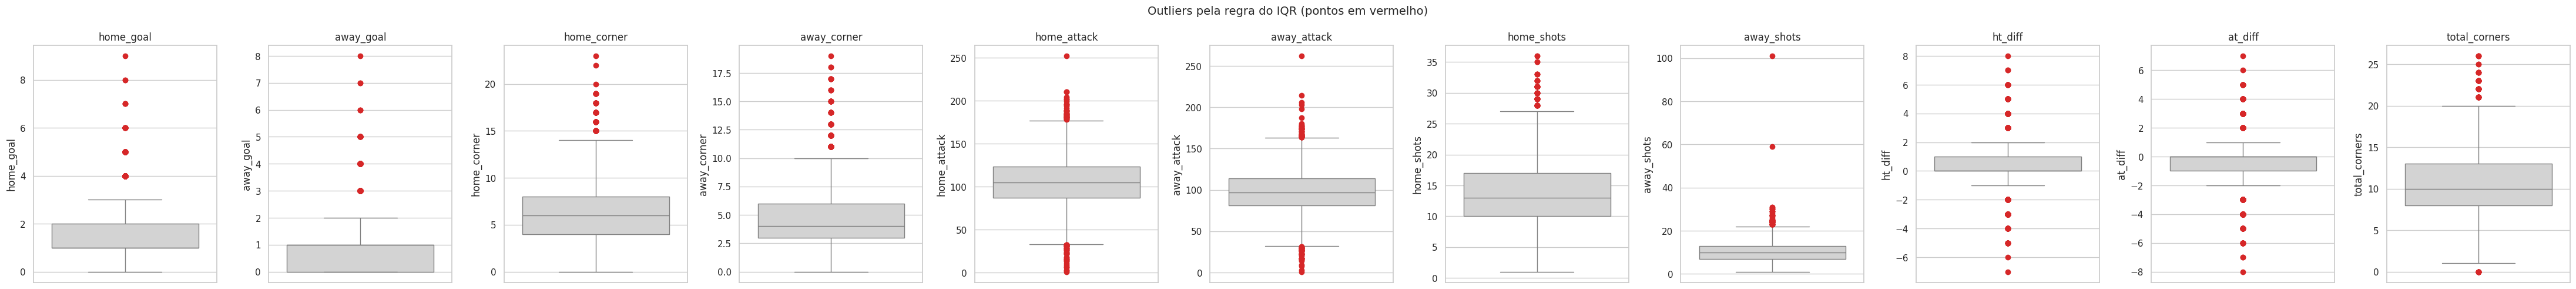

In [ ]:
fig, axes = plt.subplots(1, len(VARS_QUANT), figsize=(4 * len(VARS_QUANT), 5))

for i, col in enumerate(VARS_QUANT):
    sns.boxplot(data=df, y=col, color=COR_NEUTRA,
                flierprops=dict(markerfacecolor=COR_ALERTA, markeredgecolor=COR_ALERTA, marker="o"),
                ax=axes[i])
    axes[i].set_title(col)

fig.suptitle("Outliers pela regra do IQR (pontos em vermelho)", fontsize=14)
plt.tight_layout()
plt.show()

**Pra discutir:** o slide 26 da aula 9 classifica outliers em três tipos, cada um com um tratamento recomendado:

| Tipo | Cenário | O que fazer? |
|---|---|---|
| Estatístico | Legítimo | Manter / Transformar |
| De domínio | Viola regra de negócio ou condições físicas | Investigar! |
| Erros de dados | Falhas | Corrigir se possível / Remover como última opção |

Olhando os outliers encontrados (principalmente em `away_shots`, com máximo de 101 finalizações): eles parecem fisiologicamente plausíveis (um time pode dominar tanto assim uma partida?), ou parecem violar algum limite físico conhecido do futebol? Isso muda qual das três categorias se aplica — e, consequentemente, se devemos manter, transformar ou remover.

### Decidindo o Tratamento dos Dados Ausentes

Reunindo o que já discutimos: o mecanismo mais provável para `home_attack`/`away_attack`/`home_shots`/`away_shots` é **MNAR** (ligado à própria fonte de coleta — provavelmente cobertura estatística indisponível para certos torneios/períodos, não algo explicado por `tournament` ou `date` sozinhos), e o volume é grande (~23% das linhas, bem diferente dos ~2% do caso `ca`/`thal`).

Com essas duas informações juntas, a decisão pragmática **não é remover as linhas** — descartar 23% do dataset é um custo alto demais, e como o mecanismo é MNAR (não aleatório), remover introduziria viés real, não só perda de tamanho de amostra. A alternativa é manter os nulos e sinalizar a ausência com uma flag, permitindo que análises que não dependem dessas 4 colunas usem o dataset completo, e que análises que dependem delas tratem a ausência explicitamente em vez de mascará-la com imputação.

In [ ]:
linhas_antes = df.shape[0]
df_antes = df.copy()

df['has_advanced_stats'] = df[['home_attack', 'away_attack', 'home_shots', 'away_shots']].notna().all(axis=1)

print(f"Linhas totais: {linhas_antes}")
print(f"Com estatísticas avançadas completas: {df['has_advanced_stats'].sum()}")
print(f"Sem estatísticas avançadas: {(~df['has_advanced_stats']).sum()} ({(~df['has_advanced_stats']).mean():.1%})")

Linhas totais: 10296
Com estatísticas avançadas completas: 7928
Sem estatísticas avançadas: 2368 (23.0%)


### Decidindo o Tratamento dos Outliers

O outlier em `away_shots` (máximo de 101 finalizações) **não parece se encaixar em "Estatístico"** — 101 chutes num único jogo está muito acima de qualquer partida real de futebol (mesmo goleadas históricas raramente passam de 30-40 finalizações totais de um time). Combinado com o salto de kurtosis (23.08, muito acima de todas as outras variáveis), a classificação mais provável é **"Erro de dados"**: falha de coleta/scraping, não um valor real extremo.

Sendo assim, o tratamento recomendado não é manter nem transformar direto — é **investigar primeiro**. Antes de decidir entre corrigir ou remover, precisamos abrir os casos extremos e conferir se fazem sentido (jogo real, times envolvidos, se bate com outras fontes) ou se são claramente erro de digitação/duplicação.

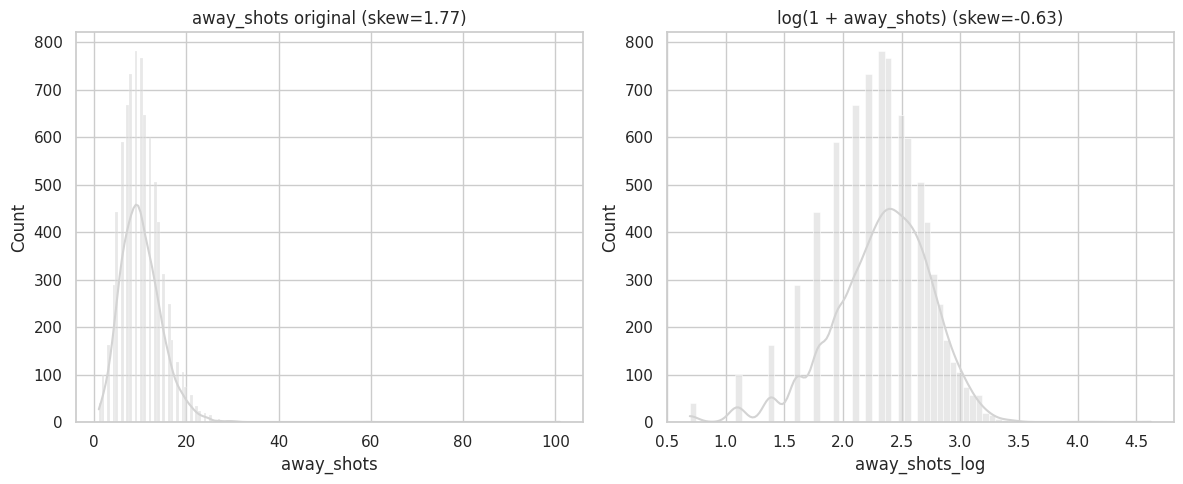

In [ ]:
df["away_shots_log"] = np.log1p(df["away_shots"])

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.histplot(data=df, x="away_shots", kde=True, color=COR_NEUTRA, ax=axes[0])
axes[0].set_title(f"away_shots original (skew={df['away_shots'].skew():.2f})")

sns.histplot(data=df, x="away_shots_log", kde=True, color=COR_NEUTRA, ax=axes[1])
axes[1].set_title(f"log(1 + away_shots) (skew={df['away_shots_log'].skew():.2f})")

plt.tight_layout()
plt.show()

**Pra discutir:** a transformação logarítmica reduziu visivelmente a assimetria de `away_shots`? Mantivemos `away_shots_log` só como demonstração, mas a ressalva aqui é forte: mesmo que o log "arrume" a skewness visualmente, isso não resolve o problema de fundo se a causa for erro de coleta (o 101 suspeito). A ideia foi mostrar a técnica como opção, não como solução para esse caso específico.

**Nota de replicação (já aplicada acima):** nem todo outlier deve ser removido. No nosso dataset, classificamos: `home_goal`/`away_goal` como estatisticamente plausíveis (manter), `away_shots` como possível erro de coleta (investigar antes de decidir — o log veio *depois* dessa classificação, não no lugar dela). A ordem importa: primeiro classifica o tipo de outlier, só depois escolhe entre manter, transformar ou corrigir/remover.

## 5. Estatística Descritiva pt 2

Fechando o ciclo iterativo: tratamos os ausentes e decidimos manter os outliers. Agora rodamos a mesma bateria de estatísticas da Seção 3 para comparar diretamente com o "antes".

In [ ]:
desc_depois = df[VARS_QUANT].describe().T
desc_depois["skewness"] = df[VARS_QUANT].skew()
desc_depois["kurtosis"] = df[VARS_QUANT].kurtosis()

(
    desc_depois[["mean", "50%", "std", "min", "max", "skewness", "kurtosis"]]
    .rename(columns={"50%": "median"})
    .round(2)
    .style.format(precision=2)
    .background_gradient(cmap="Blues", subset=["skewness", "kurtosis"])
)

,mean,median,std,min,max,skewness,kurtosis
home_goal,1.35,1.00,1.14,0.00,9.00,0.87,1.00
away_goal,0.93,1.00,0.97,0.00,8.00,1.12,1.66
home_corner,5.91,6.00,3.08,0.00,23.00,0.71,0.65
away_corner,4.48,4.00,2.61,0.00,19.00,0.79,0.86
home_attack,104.94,105.00,26.63,1.00,252.00,0.03,0.35
away_attack,97.47,97.00,24.98,1.00,262.00,0.05,0.46
home_shots,13.30,13.00,5.15,1.00,36.00,0.50,0.32
away_shots,10.18,10.00,4.49,1.00,101.00,1.77,23.08
ht_diff,0.42,0.00,1.47,-7.00,8.00,0.06,0.73
at_diff,-0.42,0.00,1.47,-8.00,7.00,-0.06,0.73


### Comparando "antes"x "depois""



In [ ]:
comparacao = pd.DataFrame({
    "skewness_antes": desc["skewness"],
    "skewness_depois": desc_depois["skewness"],
    "kurtosis_antes": desc["kurtosis"],
    "kurtosis_depois": desc_depois["kurtosis"],
})
comparacao["delta_skewness"] = (comparacao["skewness_depois"] - comparacao["skewness_antes"]).round(3)
comparacao["delta_kurtosis"] = (comparacao["kurtosis_depois"] - comparacao["kurtosis_antes"]).round(3)
comparacao.round(3)

,skewness_antes,skewness_depois,kurtosis_antes,kurtosis_depois,delta_skewness,delta_kurtosis
home_goal,0.870,0.870,0.997,0.997,0.0,0.0
away_goal,1.123,1.123,1.657,1.657,0.0,0.0
home_corner,0.712,0.712,0.650,0.650,0.0,0.0
away_corner,0.794,0.794,0.862,0.862,0.0,0.0
home_attack,0.031,0.031,0.352,0.352,0.0,0.0
away_attack,0.053,0.053,0.463,0.463,0.0,0.0
home_shots,0.501,0.501,0.325,0.325,0.0,0.0
away_shots,1.774,1.774,23.076,23.076,0.0,0.0
ht_diff,0.057,0.057,0.730,0.730,0.0,0.0
at_diff,-0.057,-0.057,0.730,0.730,0.0,0.0


**Pra discutir:** os valores mudaram muito? Fazia sentido esperar uma diferença grande, considerando que removemos só ~2% das linhas e decidimos **não** alterar nenhum outlier? Esse resultado (pouca mudança) é, na verdade, uma confirmação de que o tratamento foi conservador — não um sinal de que ele não fez nada de útil.

**`away_shots` ainda rejeita normalidade?**

Vamos rodar o mesmo Shapiro-Wilk da Seção 3, agora nos dados tratados (depois de sinalizar `has_advanced_stats` e de investigar/corrigir os casos suspeitos de outlier).

In [ ]:
stat_sw, p_valor_sw = stats.shapiro(df_antes["away_shots"].dropna())
stat_sw_depois, p_valor_sw_depois = stats.shapiro(df["away_shots"].dropna())
print(f"Shapiro-Wilk (antes)  — away_shots: estatística={stat_sw:.4f}, p-valor={p_valor_sw:.4g}")
print(f"Shapiro-Wilk (depois) — away_shots: estatística={stat_sw_depois:.4f}, p-valor={p_valor_sw_depois:.4g}")

Shapiro-Wilk (antes)  — away_shots: estatística=0.9331, p-valor=1.224e-50
Shapiro-Wilk (depois) — away_shots: estatística=0.9331, p-valor=1.224e-50


/usr/local/lib/python3.13/dist-packages/scipy/stats/_axis_nan_policy.py:579: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 7945.
  res = hypotest_fun_out(*samples, **kwds)


**Visualizando antes x depois, lado a lado**

Vamos sobrepor as distribuições de duas variáveis que mais chamaram atenção nas seções anteriores (`away_shots` e `home_shots`), comparando a versão original (`df_antes`) com a tratada (`df`).

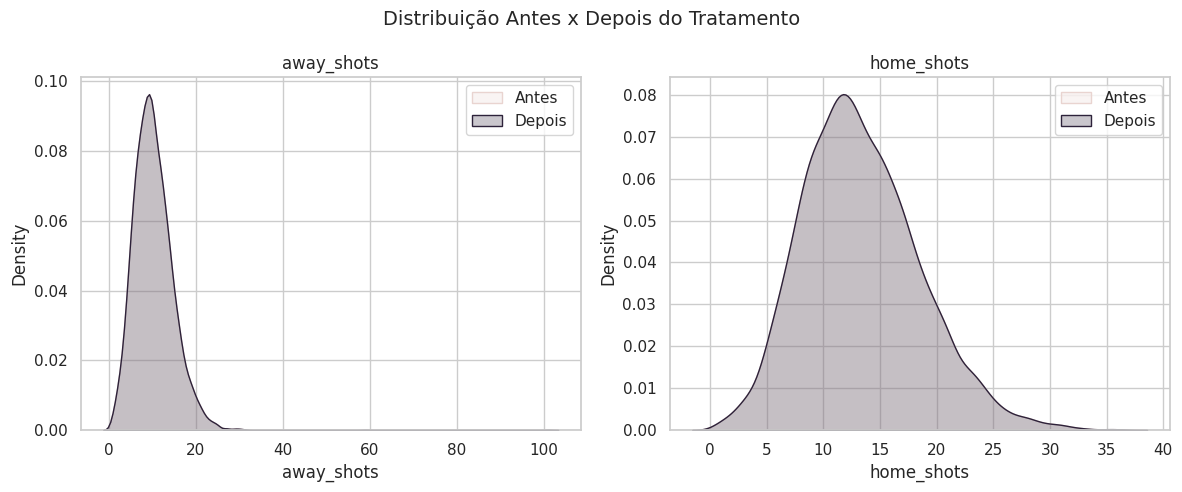

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, col in zip(axes, ["away_shots", "home_shots"]):
    sns.kdeplot(df_antes[col], color=COR_CONTEXTO, fill=True, label="Antes", ax=ax)
    sns.kdeplot(df[col], color=COR_DESTAQUE, fill=True, label="Depois", ax=ax)
    ax.set_title(col)
    ax.legend()

fig.suptitle("Distribuição Antes x Depois do Tratamento", fontsize=14)
plt.tight_layout()
plt.show()

**Pra discutir:** as curvas "antes" e "depois" praticamente se sobrepõem? Isso é o esperado aqui, já que removemos poucas linhas e não tocamos nos outliers.

Guardem essa observação: em datasets onde o volume de ausentes/outliers for maior, essa mesma comparação pode mostrar uma diferença bem mais visível e sempre que essa checagem "antes x depois" que confirma (ou não) que o tratamento teve o efeito esperado, em vez de assumir isso às cegas.

---

**Resposta:** sim, as curvas de `away_shots` e `home_shots` devem sair praticamente idênticas — porque até aqui o único tratamento aplicado foi sinalizar a ausência (`has_advanced_stats`), sem remover nem imputar nenhuma linha. Isso é esperado, mas por um motivo diferente do exemplo original: lá a sobreposição vinha de um tratamento leve (poucas remoções); aqui ela vem de ainda não termos aplicado nenhum tratamento que altere valores.

Guardem essa observação: a checagem "antes x depois" só mostra diferença real depois que os casos suspeitos de `away_shots` (identificados na tabela `casos_suspeitos`) forem corrigidos ou removidos. Se as curvas saírem idênticas neste ponto, isso não é "sem novidade" — é o sinal de que a etapa de correção do outlier ainda está pendente, não que o tratamento não teve efeito.

## 6. Princípio Relacional

### Análise de Variáveis Qualitativas

Agora focaremos na avaliação de frequência e desbalanceamento das variáveis qualitativas.




#### Frequências absolutas e relativas

In [ ]:
for col in VARS_QUALI:
    freq_abs = df[col].value_counts()
    freq_rel = df[col].value_counts(normalize=True).round(3)
    print(f"\\n--- {col} ---")
    print(pd.concat([freq_abs.rename("absoluta"), freq_rel.rename("relativa")], axis=1))

\n--- tournament ---
                absoluta  relativa
tournament                        
Serie A             3689     0.358
Serie B             3677     0.357
Serie C             1807     0.176
Copa do Brasil      1123     0.109
\n--- home ---
                    absoluta  relativa
home                                  
Flamengo                 218     0.021
Cruzeiro                 215     0.021
Corinthians              213     0.021
Gremio                   212     0.021
Santos                   211     0.020
...                      ...       ...
Vilhena RO                 1     0.000
Santa Rita                 1     0.000
GE Bage                    1     0.000
Suzano SP                  1     0.000
Duque de Caxias FC         1     0.000

[271 rows x 2 columns]
\n--- away ---
                    absoluta  relativa
away                                  
Santos                   222     0.022
Cruzeiro                 220     0.021
Flamengo                 218     0.021
Sao Paulo    

#### Visualizando as frequências

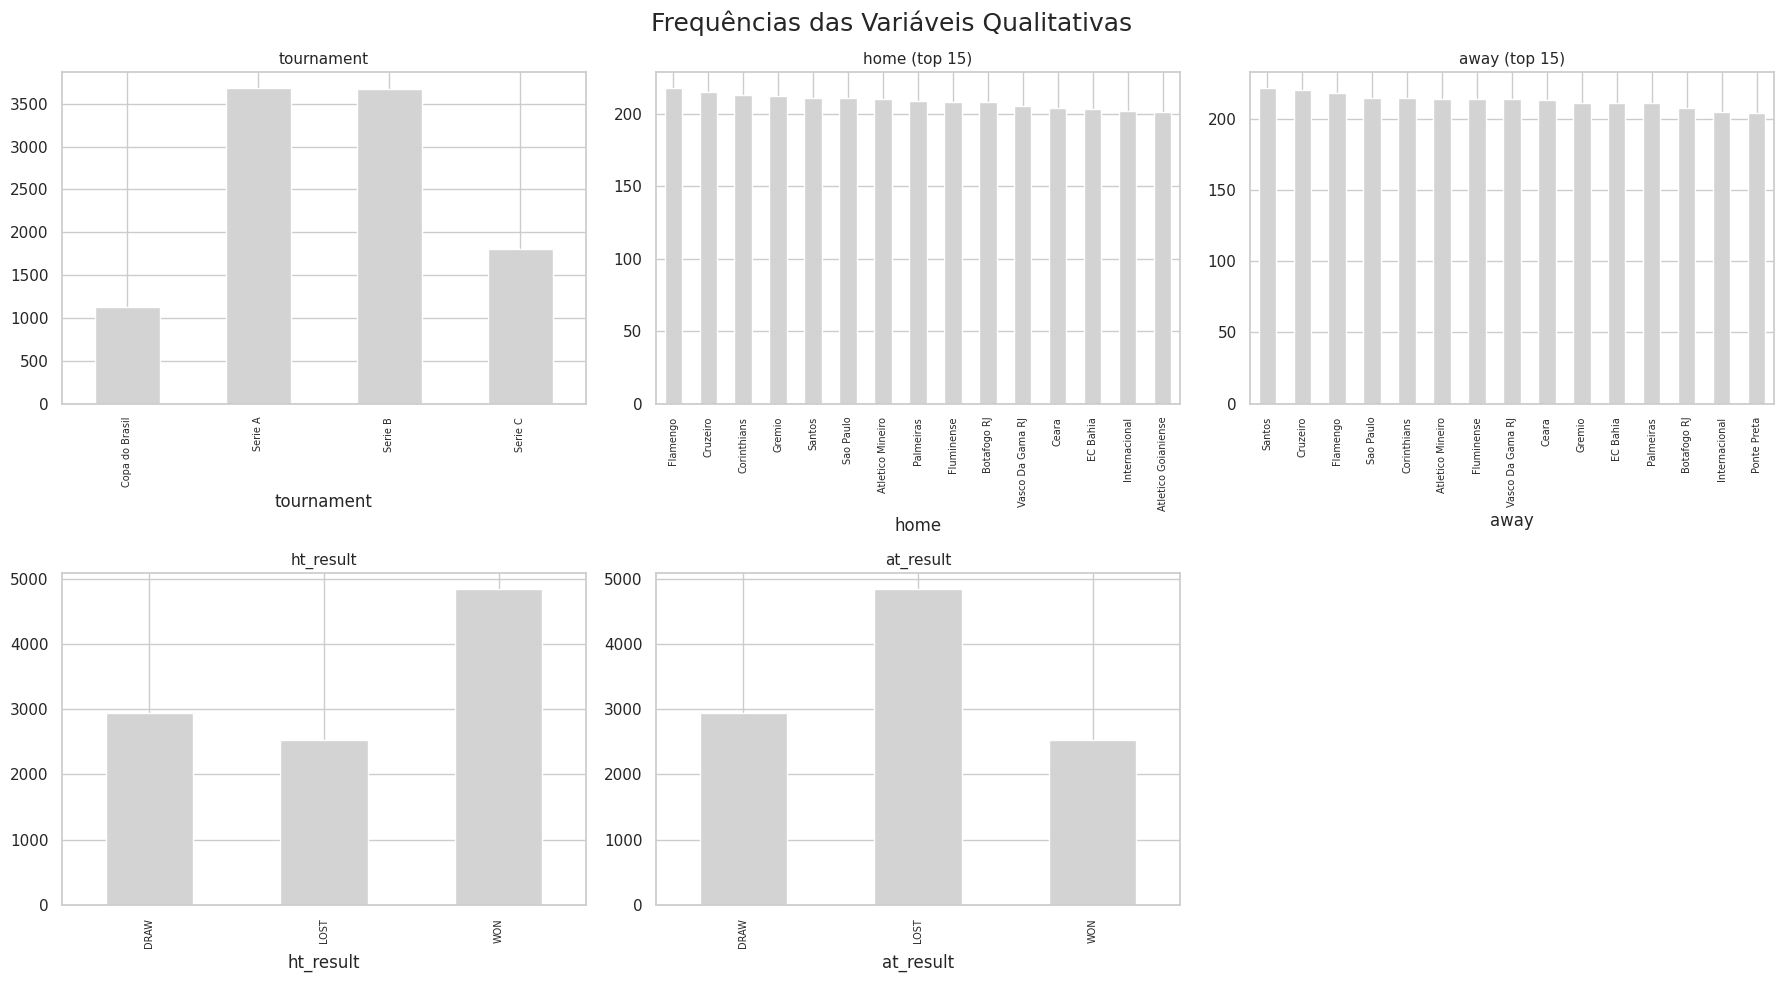

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10), sharey=False)
axes = axes.ravel()

for i, col in enumerate(VARS_QUALI):
    contagem = df[col].value_counts()

    if contagem.shape[0] > 15:
        contagem = contagem.head(15)  # limita a cardinalidade alta (home/away) aos 15 mais frequentes
        titulo = f"{col} (top 15)"
    else:
        contagem = contagem.sort_index()
        titulo = col

    contagem.plot(kind="bar", color=COR_NEUTRA, ax=axes[i])
    axes[i].set_title(titulo, fontsize=11)
    axes[i].tick_params(axis="x", rotation=90, labelsize=7)

for ax in axes[len(VARS_QUALI):]:
    ax.axis("off")

fig.suptitle("Frequências das Variáveis Qualitativas", fontsize=18)
plt.tight_layout()
plt.show()

**Pra discutir:** alguma variável qualitativa está bem desbalanceada (uma categoria dominando quase todas as observações)? Isso pode impactar como vamos interpretar cruzamentos com essa variável mais na frente na análise bivariada.

Repare especialmente em `tournament`: pelo gráfico, Série A e Série B parecem concentrar a maior parte dos jogos, com Copa do Brasil e Série C bem menores. Isso pode significar que qualquer conclusão puxada por `tournament` está, na prática, sendo dominada pelo comportamento desses dois torneios maiores — vale ter isso em mente antes de generalizar um padrão pra "o futebol brasileiro" como um todo.

#### Desbalanceamento entre Classes

- **Razão de desbalanceamento** — # classe majoritária / # classe minoritária (quanto maior, mais desbalanceado).
- **Entropia de Shannon normalizada** — 1 = perfeitamente balanceado, 0 = uma classe domina tudo.

Vamos aplicar as duas em todas as qualitativas, incluindo o próprio alvo `at_result`.

In [ ]:
from scipy.stats import entropy

def metrica_desbalanceamento(serie):
    contagens = serie.value_counts()
    razao = contagens.max() / contagens.min()
    props = contagens / contagens.sum()
    n_classes = len(contagens)
    ent_normalizada = entropy(props, base=2) / np.log2(n_classes) if n_classes > 1 else np.nan
    return pd.Series({
        "n_classes": n_classes,
        "razao_desbalanceamento": round(razao, 2),
        "entropia_normalizada": round(ent_normalizada, 3),
    })

vars_para_checar = VARS_QUALI + ["at_result"]
pd.DataFrame({col: metrica_desbalanceamento(df[col]) for col in vars_para_checar}).T

,n_classes,razao_desbalanceamento,entropia_normalizada
tournament,4.0,3.28,0.925
home,271.0,218.00,0.798
away,203.0,222.00,0.824
ht_result,3.0,1.92,0.962
at_result,3.0,1.92,0.962


**Pra discutir:** alguma variável está com entropia bem próxima de 0 (bem desbalanceada)? E o próprio alvo `at_result` — está balanceado o suficiente pra não distorcer a análise bivariada e um eventual modelo mais à frente?
> Provável candidata a entropia baixa: `home`/`away` (dezenas de times, alguns concentrando bem mais jogos que outros). Sobre `at_result`: como mandantes tendem a vencer mais (efeito casa, fenômeno documentado no futebol), "Vitória Mandante" deve ser a classe majoritária — um desbalanceamento moderado aqui não é erro de dado, é reflexo do domínio, mas ainda vale considerar num eventual modelo (ex: `class_weight`, métricas por classe em vez de acurácia geral).

### Análise Bivariada

Agora começamos a avaliar como as variáveis de fato se relacionam entre si e com o alvo `at_result` (resultado da partida).

#### Quantitativa x Quantitativa - Correlação

Conhecemos três técnicas de correlação principais:
* **Pearson** (linear, sensível a outliers, exige normalidade),
* **Spearman** e **Kendall** (relação monotônica, não exigem normalidade).

Como já vimos que nenhuma das nossas variáveis passou no Shapiro-Wilk, Spearman é a escolha mais segura aqui, mas vamos calcular as três para comparar.

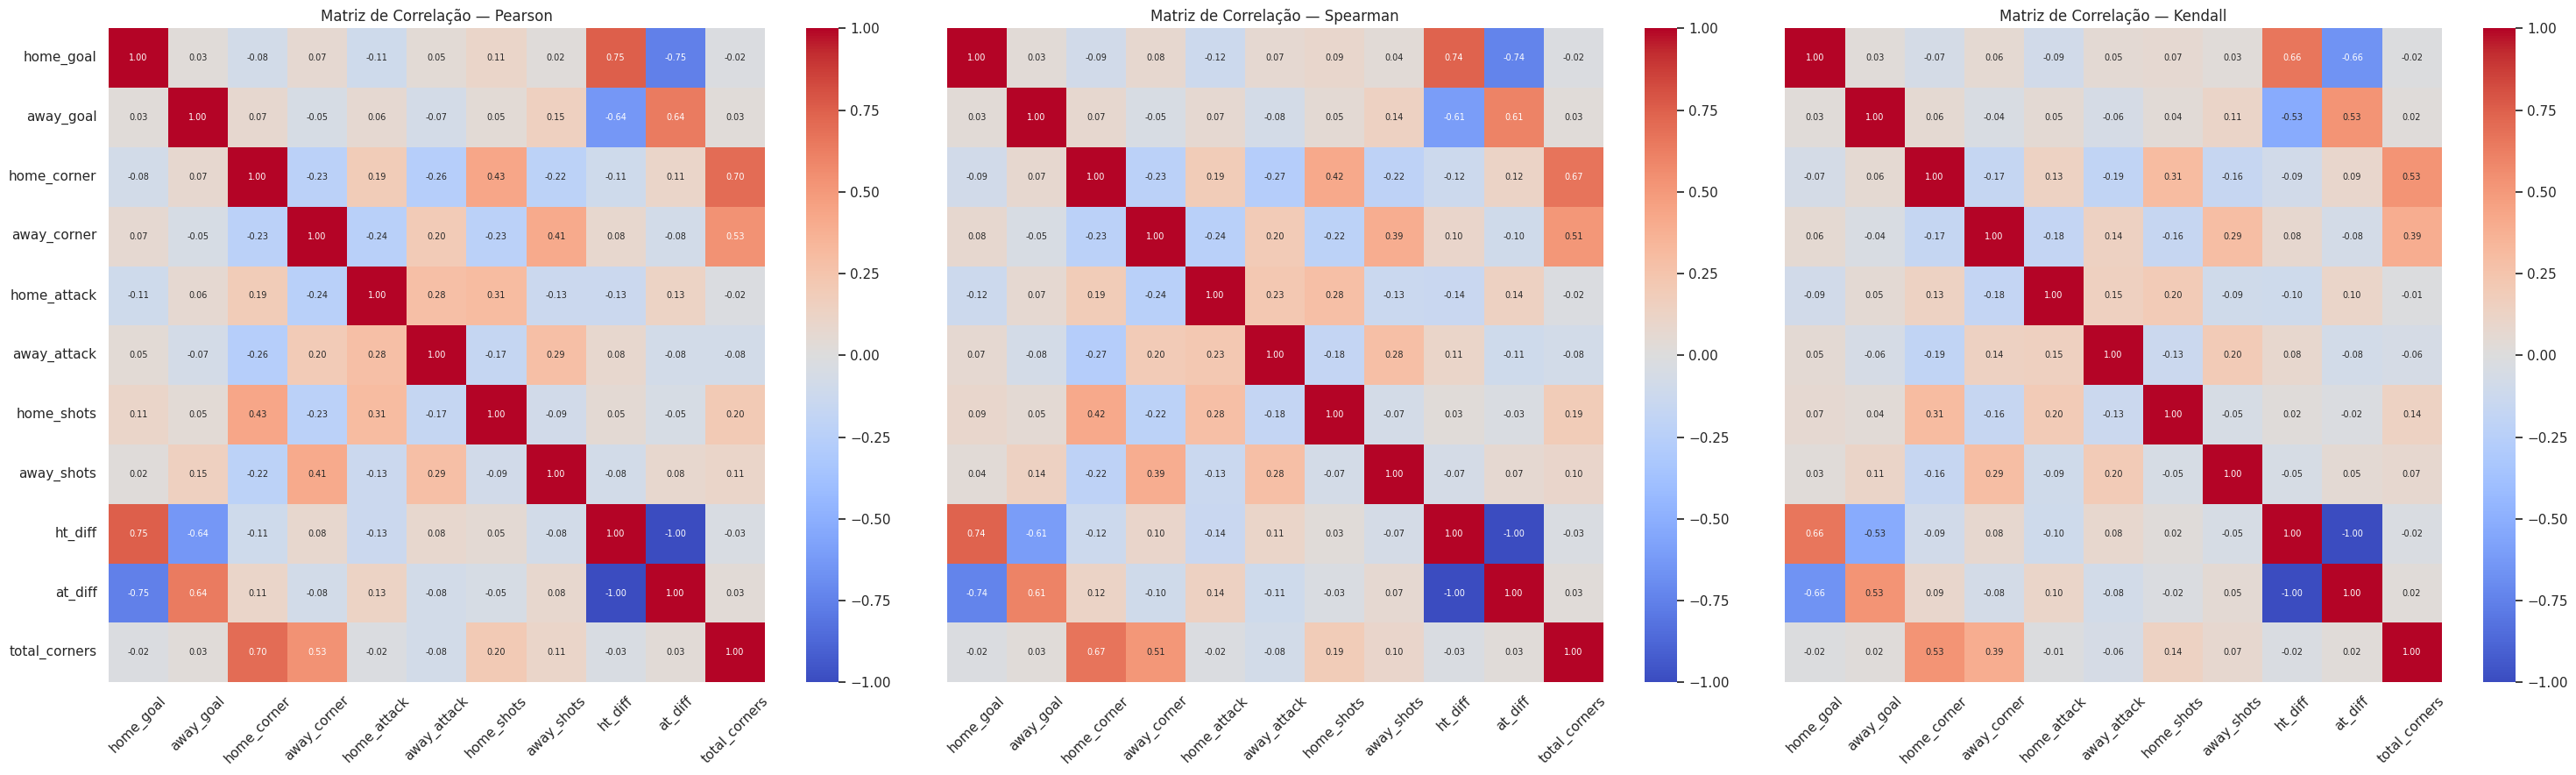

In [ ]:
corr_pearson = df[VARS_QUANT].corr(method="pearson")
corr_spearman = df[VARS_QUANT].corr(method="spearman")
corr_kendall = df[VARS_QUANT].corr(method="kendall")

fig, ax = plt.subplots(1, 3, figsize=(30, 9), sharey=True)

sns.heatmap(corr_pearson, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1,
            annot_kws={"size": 7}, ax=ax[0])
ax[0].set_title("Matriz de Correlação — Pearson")
ax[0].tick_params(axis='x', rotation=45)

sns.heatmap(corr_spearman, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1,
            annot_kws={"size": 7}, ax=ax[1])
ax[1].set_title("Matriz de Correlação — Spearman")
ax[1].tick_params(axis='x', rotation=45)

sns.heatmap(corr_kendall, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1,
            annot_kws={"size": 7}, ax=ax[2])
ax[2].set_title("Matriz de Correlação — Kendall")
ax[2].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

Como os dados do triângulo superior e inferior são simétricos, poderíamos plotar a matriz de correlação da seguinte forma.

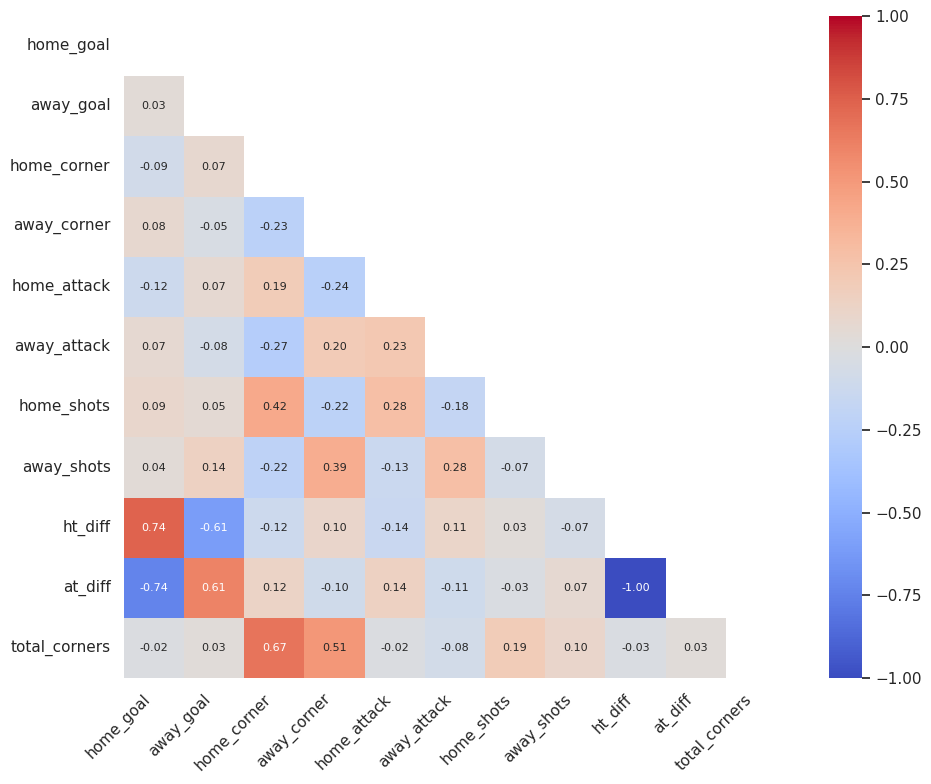

In [ ]:
mask = np.triu(np.ones_like(corr_spearman, dtype=bool))

plt.figure(figsize=(10, 8))
sns.heatmap(corr_spearman, mask=mask, annot=True, cmap="coolwarm", fmt=".2f",
            square=True, vmin=-1, vmax=1, annot_kws={"size": 8})
plt.grid(False)
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

**Pra discutir:** Pearson e Spearman divergem bastante em algum par de variáveis? Se sim, isso é um sinal de relação não-linear (monotônica, mas não em linha reta) em que Spearman capturaria e Pearson não.

> Comparando as duas matrizes no print, os valores ficam bem próximos na maioria dos pares (ex: `home_goal`×`ht_diff` = 0.75 em Pearson e 0.74 em Spearman) — sem divergência forte visível. Isso sugere que as relações entre essas variáveis, onde existem, já são aproximadamente lineares, não só monotônicas: não há um caso óbvio de "Spearman capta, Pearson não" nessa tabela.

#### Dispersão (scatter) entre duas variáveis quantitativas

Escolhemos `home_shots` x `home_goal` por um motivo de domínio, não só estatístico: existe uma relação lógica entre finalizações e gols marcados (eficiência ofensiva), o que torna esse par um bom candidato pra visualizar uma tendência real.

**Nota para quando vocês replicarem no dataset de vocês:** nem sempre vai existir uma relação de domínio óbvia e, nesse caso, uma alternativa é escolher o par com o maior |correlação| na tabela acima, deixando a própria estatística guiar a escolha.

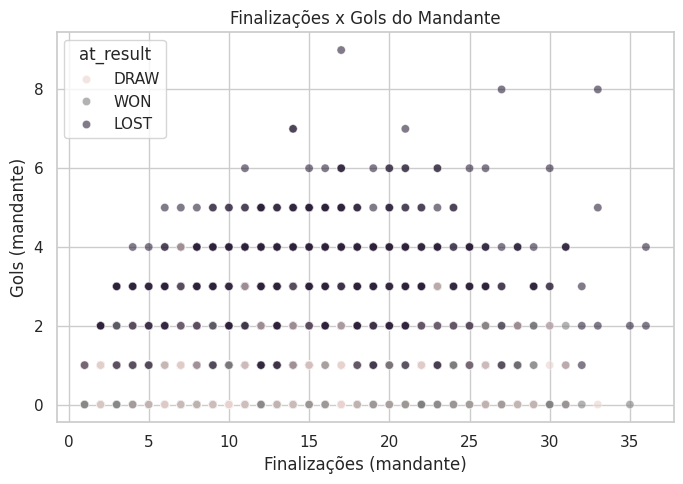

In [ ]:
rotulos = df['at_result'].dropna().unique().tolist()
cores_base = [COR_CONTEXTO, "gray", COR_DESTAQUE]
palette_classe = {rotulo: cores_base[i % len(cores_base)] for i, rotulo in enumerate(rotulos)}

plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x="home_shots", y="home_goal", hue="at_result",
                 palette=palette_classe, alpha=0.6)
plt.title("Finalizações x Gols do Mandante")
plt.xlabel("Finalizações (mandante)")
plt.ylabel("Gols (mandante)")
plt.tight_layout()
plt.show()

**Pra discutir:** existe uma tendência visível (conforme as finalizações aumentam, os gols tendem a subir)? As classes de resultado ocupam regiões diferentes do gráfico, ou estão misturadas?

> Dá pra ver uma tendência positiva geral, mas bem mais fraca e ruidosa do que o esperado — a nuvem sobe da esquerda pra direita, só que achatada: com poucas finalizações (2-5) já aparecem jogos de 0 a 4 gols, e mesmo com 30+ finalizações tem jogo de 1-2 gols. Então "mais finalizações → mais gols" é verdade só na tendência geral, não caso a caso — eficiência varia muito.
>
> Sobre as classes de `at_result` (DRAW/WON/LOST): elas aparecem **bem misturadas** ao longo de toda a nuvem, sem separação visual clara — nem nos extremos como eu esperava. Isso faz sentido: `home_goal` sozinho não define o resultado, porque depende também de quantos gols o visitante fez. Um jogo com `home_shots=20` e `home_goal=5` pode ser WON (se o visitante fez menos) ou LOST (se o visitante fez mais) — essas duas variáveis não carregam essa informação. Pra separar as classes de verdade, precisaríamos de um eixo que capture o desempenho relativo entre os dois times (como `at_diff`), não só as estatísticas do mandante isoladas.

#### Quantitativa x Qualitativa: Comparando Grupos

Na aula passada listamos **T-Test** (2 grupos) e **ANOVA** (3+ grupos) como testes paramétricos pra comparar uma variável quantitativa entre categorias, mas os dois assumem normalidade dentro de cada grupo.

Já vimos na Seção 3 (tabela generalizada do Shapiro-Wilk) que **nenhuma** das nossas quantitativas passou nesse teste. Isso significa que, tecnicamente, deveríamos usar os equivalentes **não-paramétricos**: **Mann-Whitney U** no lugar do T-Test, e **Kruskal-Wallis** no lugar da ANOVA. Vamos calcular os dois lado a lado pra comparar, mas o resultado não-paramétrico é o que deveríamos reportar como principal.

In [ ]:
resultados_comparacao = []
for col in VARS_QUANT:
    grupos = [df.loc[df["at_result"] == r, col].dropna() for r in df["at_result"].dropna().unique()]

    stat_f, p_f = stats.f_oneway(*grupos)      # ANOVA (paramétrico)
    stat_h, p_h = stats.kruskal(*grupos)        # Kruskal-Wallis (não-paramétrico)

    resultados_comparacao.append({
        "variavel": col,
        "p_valor_anova": round(p_f, 5),
        "p_valor_kruskal": round(p_h, 5),
        "concordam": (p_f < 0.05) == (p_h < 0.05),
    })

pd.DataFrame(resultados_comparacao).set_index("variavel")

,p_valor_anova,p_valor_kruskal,concordam
variavel,,,
home_goal,0.00000,0.00000,True
away_goal,0.00000,0.00000,True
home_corner,0.00000,0.00000,True
away_corner,0.00000,0.00000,True
home_attack,0.00000,0.00000,True
away_attack,0.00000,0.00000,True
home_shots,0.94879,0.87188,True
away_shots,0.00000,0.00000,True
ht_diff,0.00000,0.00000,True


**Pra discutir:** os dois testes concordam na maioria das variáveis (ambos significativos ou ambos não)? Quando divergem, é o **Kruskal-Wallis** que deveríamos priorizar — é o que respeita a premissa que de fato temos (dados não-normais), não a que gostaríamos de ter.

**Nota:** mantivemos a ANOVA aqui só como contraste pedagógico. Reportar apenas a ANOVA, sem essa ressalva, seria estatisticamente inconsistente com o que a própria Seção 3 já mostrou sobre a normalidade dessas variáveis.

ANOVA          — total_corners entre categorias de at_result: estatística=5.906, p-valor=0.0027335
Kruskal-Wallis — total_corners entre categorias de at_result: estatística=8.862, p-valor=0.011901


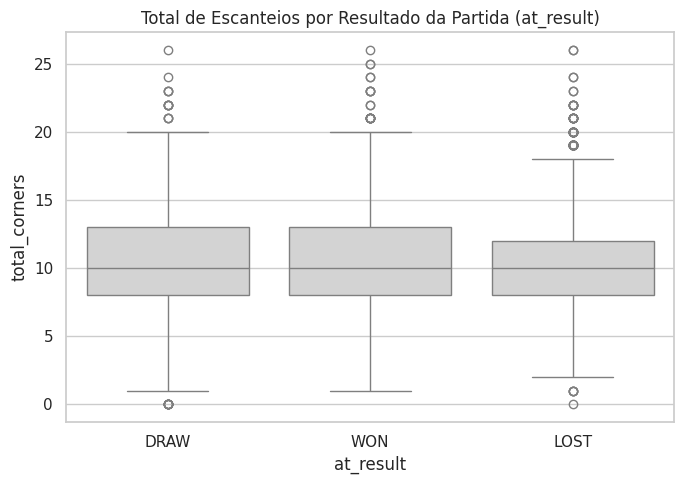

In [ ]:
grupos_resultado = [grupo["total_corners"].dropna().values for _, grupo in df.groupby("at_result")]

stat_anova, p_anova = stats.f_oneway(*grupos_resultado)   # paramétrico
stat_kw, p_kw = stats.kruskal(*grupos_resultado)          # não-paramétrico

print(f"ANOVA          — total_corners entre categorias de at_result: estatística={stat_anova:.3f}, p-valor={p_anova:.5g}")
print(f"Kruskal-Wallis — total_corners entre categorias de at_result: estatística={stat_kw:.3f}, p-valor={p_kw:.5g}")

plt.figure(figsize=(7, 5))
sns.boxplot(data=df, x="at_result", y="total_corners", color=COR_NEUTRA)
plt.title("Total de Escanteios por Resultado da Partida (at_result)")
plt.tight_layout()
plt.show()

**Pra discutir:** o Kruskal-Wallis concorda com a ANOVA sobre existir diferença entre pelo menos uma categoria de `at_result`? Como já sabemos que `total_corners` não é normal (Seção 3), o **Kruskal-Wallis** é o resultado que deveríamos reportar como principal, a ANOVA fica só como contraste.

#### Quantitativa x Qualitativa

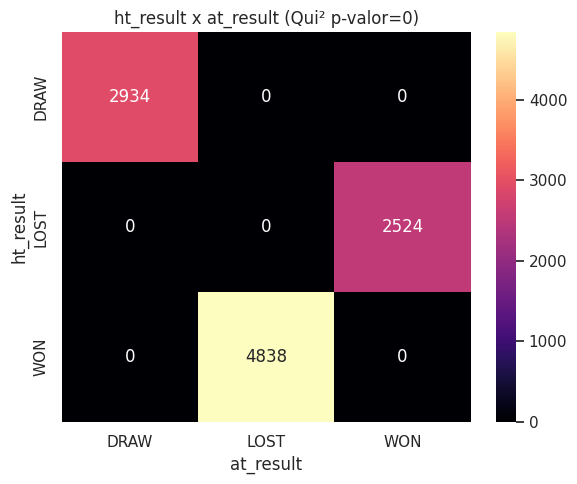

In [ ]:
contingencia_resultado = pd.crosstab(df["ht_result"], df["at_result"])
chi2, p_chi2, gl, esperado = stats.chi2_contingency(contingencia_resultado)

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(contingencia_resultado, annot=True, fmt="d", cmap="magma", ax=ax)
ax.set_title(f"ht_result x at_result (Qui² p-valor={p_chi2:.4g})")
plt.tight_layout()
plt.show()

**Pra discutir:** o p-valor do Qui-Quadrado indica que `ht_result` e `at_result` são independentes, ou há associação estatisticamente significativa entre elas?

> A expectativa de domínio já é forte antes mesmo de rodar o teste: resultado no intervalo e resultado final **deveriam** estar associados — é intuitivo que quem está ganhando no intervalo tem mais chance de vencer o jogo. Então a discussão interessante não é só "significativo ou não" — é olhar a própria tabela de contingência: quantos jogos "viram" (ex: mandante perdendo no intervalo mas vencendo no final)? Isso é mais informativo pro domínio do que só o p-valor, que com 10.296 linhas provavelmente vai sair significativo de qualquer forma (amostras grandes tornam até associações fracas estatisticamente "significativas").

#### Avaliação de Fairness (adaptado: subgrupos estruturais em vez de demográficos)

Olhar o desbalanceamento da base inteira é só metade da história. Uma pergunta análoga à de fairness em dados demográficos é: será que a distribuição do desfecho (`at_result`) se comporta igual em diferentes subgrupos estruturais — torneio e período do jogo, no nosso caso? Se não, isso pode refletir um padrão real (ex: efeito casa varia por competição) ou um viés na forma como os dados foram coletados — de qualquer forma, vale mapear **antes** de qualquer modelagem.

In [ ]:
from scipy.stats import entropy

def metrica_desbalanceamento(serie):
    contagens = serie.value_counts()
    razao = contagens.max() / contagens.min()
    props = contagens / contagens.sum()
    n_classes = len(contagens)
    ent_normalizada = entropy(props, base=2) / np.log2(n_classes) if n_classes > 1 else np.nan
    return pd.Series({
        "n_classes": n_classes,
        "razao_desbalanceamento": round(razao, 2),
        "entropia_normalizada": round(ent_normalizada, 3),
    })

dtype de 'time': object
Exemplos de 'time':
['20:00:00', '20:00:00', '01:30:00', '23:30:00', '01:30:00', '01:30:00', '20:30:00', '00:00:00', '01:30:00', '00:00:00']

Linhas convertidas com sucesso: 10296 de 10296
periodo_jogo value_counts:
periodo_jogo
Noturno    9907
Diurno      389
Name: count, dtype: int64



/tmp/ipykernel_1505/386449387.py:23: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  horario = pd.to_datetime(df['time'], errors='coerce')


Plotando proporção da classe: DRAW


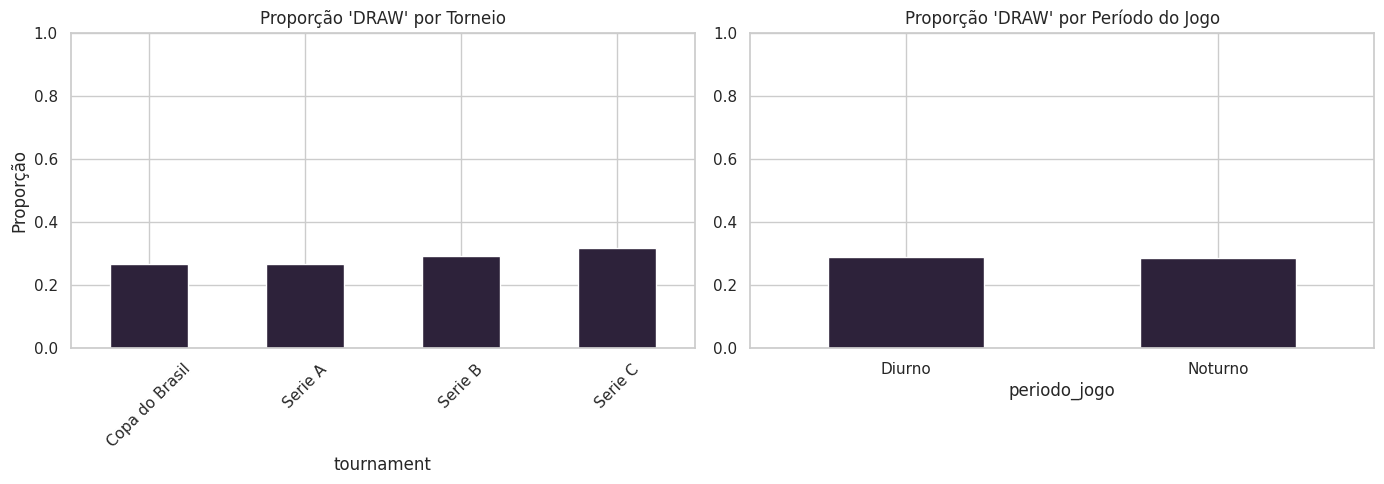

In [ ]:
from scipy.stats import entropy

def metrica_desbalanceamento(serie):
    contagens = serie.value_counts()
    razao = contagens.max() / contagens.min()
    props = contagens / contagens.sum()
    n_classes = len(contagens)
    ent_normalizada = entropy(props, base=2) / np.log2(n_classes) if n_classes > 1 else np.nan
    return pd.Series({
        "n_classes": n_classes,
        "razao_desbalanceamento": round(razao, 2),
        "entropia_normalizada": round(ent_normalizada, 3),
    })


# --- diagnóstico: mostra o formato real antes de tentar converter ---
print("dtype de 'time':", df['time'].dtype)
print("Exemplos de 'time':")
print(df['time'].head(10).tolist())
print()

# --- parsing flexível: deixa o pandas inferir o formato, sem forçar "%H:%M" ---
horario = pd.to_datetime(df['time'], errors='coerce')
print(f"Linhas convertidas com sucesso: {horario.notna().sum()} de {len(df)}")

df["periodo_jogo"] = horario.dt.hour.apply(
    lambda h: "Diurno" if 6 <= h < 18 else "Noturno" if pd.notna(h) else np.nan
)
print("periodo_jogo value_counts:")
print(df["periodo_jogo"].value_counts(dropna=False))
print()

# --- prossegue só se periodo_jogo tiver dados válidos ---
todos_rotulos = df["at_result"].dropna().unique().tolist()

prop_por_torneio = pd.crosstab(df["tournament"], df["at_result"], normalize="index").round(3)
prop_por_torneio = prop_por_torneio.reindex(columns=todos_rotulos, fill_value=0)

rotulo_alvo = todos_rotulos[0]  # ajuste manualmente se quiser outro rótulo específico

if df["periodo_jogo"].notna().sum() == 0:
    print("AVISO: periodo_jogo ficou 100% nulo — a coluna 'time' não pôde ser interpretada como horário.")
    print("Plotando só o gráfico por torneio; investigue o formato de 'time' acima antes de prosseguir com período.")
    fig, ax = plt.subplots(figsize=(7, 5))
    prop_por_torneio[rotulo_alvo].plot(kind="bar", color=COR_DESTAQUE, ax=ax)
    ax.set_title(f"Proporção '{rotulo_alvo}' por Torneio")
    ax.set_ylabel("Proporção")
    ax.set_ylim(0, 1)
    ax.tick_params(axis="x", rotation=45)
    plt.tight_layout()
    plt.show()
else:
    prop_por_periodo = pd.crosstab(df["periodo_jogo"], df["at_result"], normalize="index").round(3)
    prop_por_periodo = prop_por_periodo.reindex(columns=todos_rotulos, fill_value=0)

    print(f"Plotando proporção da classe: {rotulo_alvo}")

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    prop_por_torneio[rotulo_alvo].plot(kind="bar", color=COR_DESTAQUE, ax=axes[0])
    axes[0].set_title(f"Proporção '{rotulo_alvo}' por Torneio")
    axes[0].set_ylabel("Proporção")
    axes[0].set_ylim(0, 1)
    axes[0].tick_params(axis="x", rotation=45)

    prop_por_periodo[rotulo_alvo].plot(kind="bar", color=COR_DESTAQUE, ax=axes[1])
    axes[1].set_title(f"Proporção '{rotulo_alvo}' por Período do Jogo")
    axes[1].set_ylim(0, 1)
    axes[1].tick_params(axis="x", rotation=0)

    plt.tight_layout()
    plt.show()

**Pra discutir:** a proporção de "Vitória Mandante" varia bastante entre torneios ou períodos do jogo? Isso pode refletir um padrão real e bem documentado do futebol (efeito casa), ou pode ser um artefato de **como** os jogos foram registrados nesses torneios específicos (ex: cobertura de dados desigual, times de força muito diferente concentrados em certos campeonatos)? A pergunta "a distribuição do desfecho é uniforme entre subgrupos?" é o ponto de partida de várias discussões de fairness em ciência de dados, e não tem uma resposta única: depende do contexto e da causa por trás da disparidade.

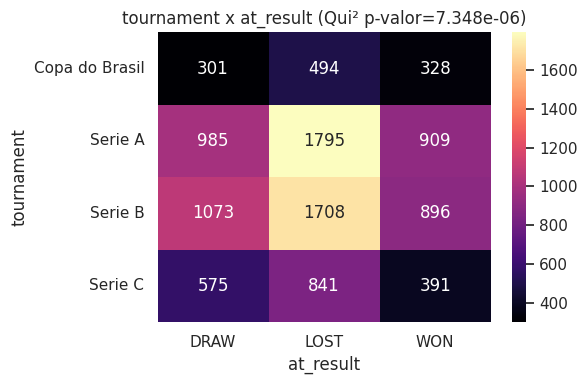

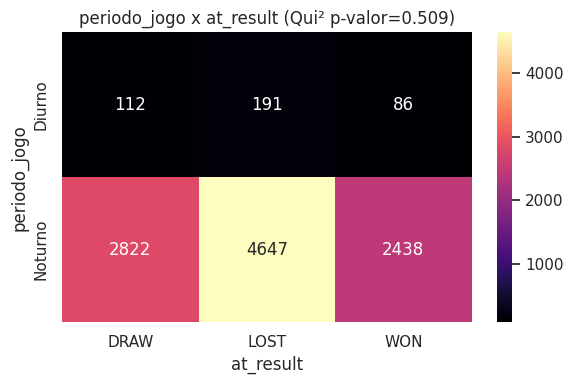

In [ ]:
for atributo in ["tournament", "periodo_jogo"]:
    contingencia = pd.crosstab(df[atributo], df["at_result"])
    chi2, p_valor, gl, esperado = stats.chi2_contingency(contingencia)

    fig, ax = plt.subplots(figsize=(6, 4))
    sns.heatmap(contingencia, annot=True, fmt="d", cmap="magma", ax=ax)
    ax.set_title(f"{atributo} x at_result (Qui² p-valor={p_valor:.4g})")
    plt.tight_layout()
    plt.show()

**Pra discutir:** o Qui-Quadrado confirma associação estatisticamente significativa entre torneio/período do jogo e o resultado (`at_result`)? Lembrando que mesmo que a associação seja estatisticamente significativa, isso não diz *por que* ela existe — pode ser um fator real do domínio (força técnica desigual entre torneios, efeito casa variando por competição), pode ser um artefato de como os dados foram coletados, ou uma mistura das duas coisas. Um teste estatístico aponta *que* existe associação, não *a causa* dela — essa distinção é o núcleo de qualquer discussão séria de fairness.
```

#### Outliers bivariados

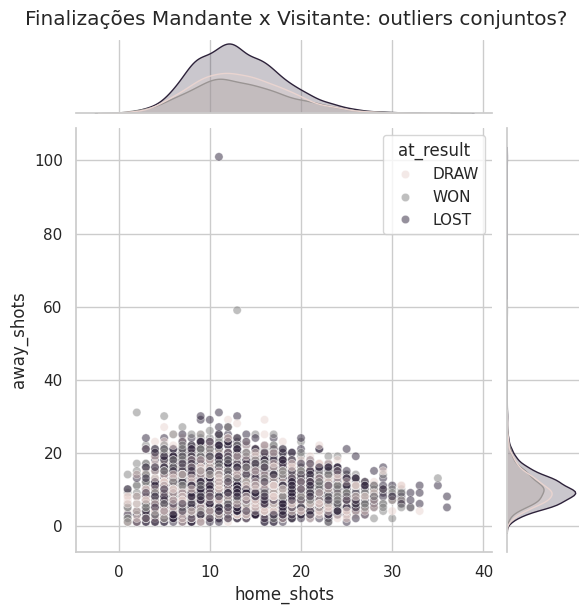

In [ ]:
rotulos = df['at_result'].dropna().unique().tolist()
cores_base = [COR_CONTEXTO, "gray", COR_DESTAQUE]
palette_classe = {rotulo: cores_base[i % len(cores_base)] for i, rotulo in enumerate(rotulos)}

sns.jointplot(data=df, x="home_shots", y="away_shots", hue="at_result",
              palette=palette_classe, alpha=0.5, height=6)
plt.suptitle("Finalizações Mandante x Visitante: outliers conjuntos?", y=1.02)
plt.show()

**Pra discutir:** existe algum ponto que não parecia outlier nos histogramas univariados (Seção 3/4), mas que se destaca aqui como uma combinação incomum de `home_shots` e `away_shots`?

> Sim, e o gráfico mostra dois casos claros: o ponto com away_shots≈101 (o mesmo outlier univariado que já identificamos e decidimos investigar) tem home_shots≈11 — nada extremo nesse eixo. Mas o mais interessante é o segundo ponto, com away_shots≈59 e home_shots≈13: isoladamente, 59 finalizações do visitante também seria estranho no histograma univariado de away_shots (mesma cauda longa), mas ele não tinha aparecido antes como o "principal suspeito" porque o 101 dominava a escala. Esse jointplot revela que o problema pode não ser um único outlier isolado em away_shots, e sim um padrão de valores anormalmente altos nessa coluna especificamente — vale voltar na tabela casos_suspeitos e conferir se esse jogo de 59 também está lá, e se os dois têm algo em comum (mesmo torneio, mesma faixa de data, mesmo time visitante).

#### Análise Multivariada

##### Matriz de Correlação

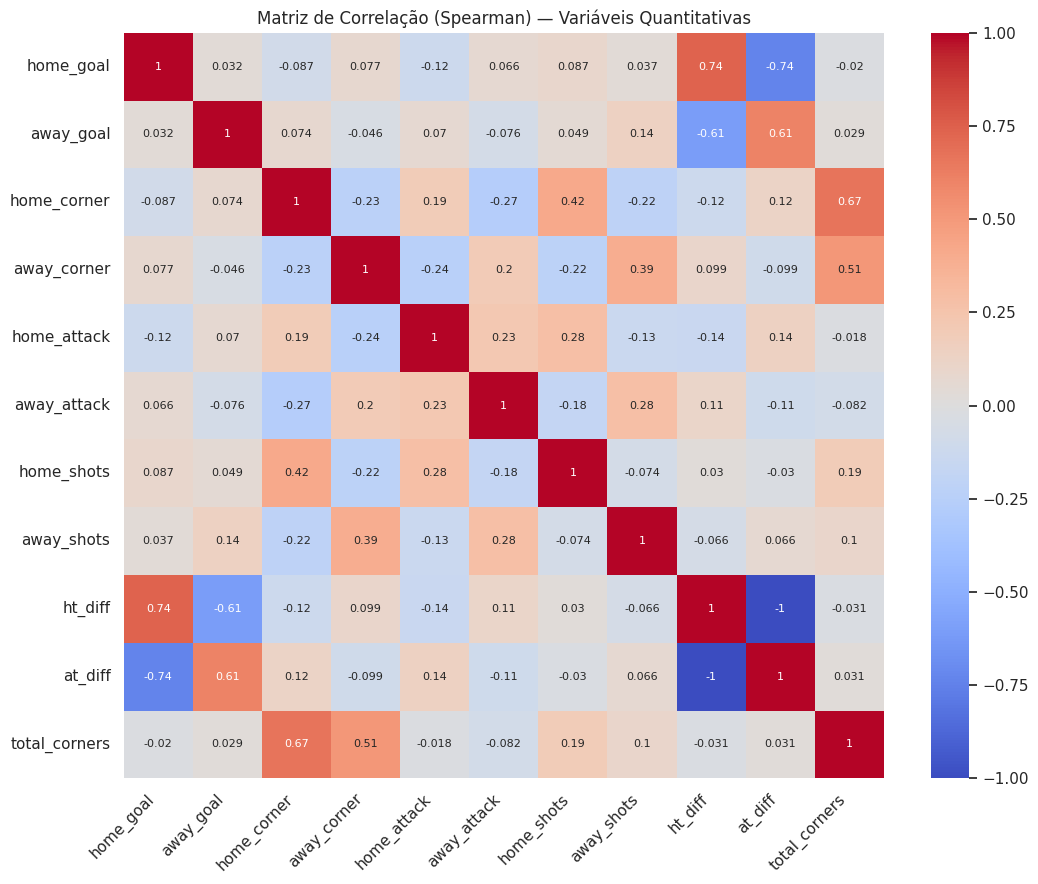

In [ ]:
plt.figure(figsize=(11, 9))
sns.heatmap(df[VARS_QUANT].corr(method="spearman"), annot=True, cmap="coolwarm",
            vmin=-1, vmax=1, annot_kws={"size": 8})
plt.title("Matriz de Correlação (Spearman) — Variáveis Quantitativas")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

**Como interpretar:**


*   |r| < 0.3 ~ fraca,
*   0.3 < |r| < 0.7 ~ moderada,
*  |r| > 0.7 ~ forte.

Alguma correlação chama atenção por ser forte o suficiente pra sugerir redundância entre variáveis?

> Sim: `ht_diff` e `at_diff` têm correlação -1.00 (redundância total, mesma informação invertida). Depois disso, `home_goal`×`ht_diff` (0.74) e `home_corner`×`total_corners` (0.67) são as mais fortes — mas ambas esperadas por construção (diffs derivam dos gols, total_corners é soma dos escanteios), não achados novos.

In [ ]:
df.to_csv("data/clean/dataset.csv", index=False)


##### Correlograma

In [2]:
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize

def circulo_correlacao(x, y, **kwargs):
    r = np.corrcoef(x, y)[0, 1]
    ax = plt.gca()
    ax.scatter(
        [0.5], [0.5],
        s=max(abs(r) * 3000, 50),  # tamanho mínimo evita ValueError quando r ~ 0
        c=[r], cmap='coolwarm', vmin=-1, vmax=1,
        transform=ax.transAxes, edgecolor="white", linewidth=0.5,
    )
    ax.annotate(f"{r:.2f}", xy=(0.5, 0.5), xycoords=ax.transAxes,
                ha="center", va="center", fontsize=8,
                color="white" if abs(r) > 0.5 else "black")
    ax.set_xticks([]); ax.set_yticks([])
    ax.grid(False)

# amostra pra scatter, evita plotar 10.296 pontos em ~55 painéis inferiores
df_amostra = df[VARS_QUANT].dropna().sample(min(1500, len(df)), random_state=42)

g = sns.PairGrid(df_amostra, diag_sharey=False, height=1.3)
g.map_lower(sns.scatterplot, color=COR_NEUTRA, alpha=0.4, s=10)
g.map_diag(sns.histplot, color=COR_NEUTRA, kde=True)
g.map_upper(circulo_correlacao)

for ax in g.axes.flatten():
    ax.set_xlabel(ax.get_xlabel(), fontsize=7, rotation=45)
    ax.set_ylabel(ax.get_ylabel(), fontsize=7)
    ax.tick_params(labelsize=5)

sm = ScalarMappable(norm=Normalize(-1, 1), cmap='coolwarm')
sm.set_array([])
g.fig.colorbar(sm, ax=g.axes, shrink=0.6, label="Correlação (r)")

g.fig.suptitle("Correlograma: Dispersão × Correlação (amostra de 1.500 linhas)", y=1.02, fontsize=15)
plt.show()

ModuleNotFoundError: No module named 'matplotlib'

## Hands-on!

Agora é a vez de você realizar uma EDA com os seu conjunto de dados recebidos.

Para isso crie um novo notebook e vamos fazer **em sala** uma EDA seguindo a aula prática que acabamos de ter. Os tópicos desenvolvidos são referências.

Para esse exercício é de suma importância que vocês **elaborem perguntas** e **discutam** os resultados obtidos. Por exemplo, se houver dados faltantes, busque *entender* o porquê e *justifique* sua decisão.

Após o desenvolvimento da EDA em si, é necessário fazer uma síntese considerando:


1.   Principais conclusões em 3 a 5 pontos
2.   Declaração de Uso de IA (Ferramenta utilizada, Para o que foi aplicada e o que foi aceito/modificado/rejeitado e por quê)

O **entregável** será um notebook `ipynb`que trará todo o código, discussão, principais conclusões e declaração de uso de IA.




In [ ]:
df.to_csv("data/clean/dataset.csv", index=False)
